In [3]:
import os
import re
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (7, 4.5)

# Directory containing the BayeSN output files. Edit this if your files live elsewhere.
DATA_DIR = Path("../results/results_subset")

def find_file(*candidates):
    """Return the first candidate filename that exists in DATA_DIR."""
    for c in candidates:
        p = DATA_DIR / c
        if p.exists():
            return p
    raise FileNotFoundError(f"None of {candidates} found in {DATA_DIR.resolve()}")

YAML_PATH     = find_file("input.yaml")
FITRES_PATH   = find_file("output.FITRES.TEXT", "output_FITRES.TEXT")
LCSUMM_PATH   = find_file("output.LCSUMMARY.TEXT", "output_LCSUMMARY.TEXT")
SUMMARY_PATH  = find_file("fit_summary.csv")
CHAINS_PATH   = DATA_DIR / "chains.pkl" 

print("Using files:")
for p in [YAML_PATH, FITRES_PATH, LCSUMM_PATH, SUMMARY_PATH]:
    print(" ", p)
print("  chains.pkl:", "found" if CHAINS_PATH.exists() else "NOT provided")

Using files:
  ../results/results_subset/input.yaml
  ../results/results_subset/output.FITRES.TEXT
  ../results/results_subset/output.LCSUMMARY.TEXT
  ../results/results_subset/fit_summary.csv
  chains.pkl: NOT provided


In [4]:
with open(YAML_PATH) as f:
    config = yaml.safe_load(f)

for k, v in config.items():
    print(f"{k:25s}: {v}")


SNID_keep_list           : None
batch_size               : 1000
chain_method             : parallel
drop_bands               : []
error_floor              : 0.0
filters                  : None
fit_method               : mcmc
initialisation           : median
jobid                    : 1
jobsplit                 : [1, 1]
keep_list                : None
l_knots                  : [2800.0, 4900.0, 6200.0, 7700.0, 8700.0, 10800.0]
laplace_method           : lm
lc_cuts                  : {}
lm_lam_init              : 1.0
lm_maxiter               : 30
lm_use_linesearch        : True
load_model               : G26_model
map                      : {'g': 'g_LSST', 'i': 'i_LSST', 'r': 'r_LSST', 'u': 'u_LSST', 'y': 'y_LSST', 'z': 'z_LSST'}
min_bin_gain             : 0.05
mode                     : fitting
njobtot                  : 1
num_chains               : 4
num_lcplot               : 0
num_nobs_bins            : 1
num_samples              : 250
num_warmup               : 250
num_zltn_iter   

In [5]:
n_chains  = config.get("num_chains")
n_samples = config.get("num_samples")
n_warmup  = config.get("num_warmup")
n_tau     = len(config.get("tau_knots", []))
n_l       = len(config.get("l_knots", []))

print(f"Posterior draws per SN : {n_chains} chains x {n_samples} samples = {n_chains*n_samples}")
print(f"Warmup draws per chain : {n_warmup}")
print(f"eps grid                : {n_tau} tau knots x {n_l} wavelength knots "
      f"= up to {n_tau*n_l} eps parameters per SN (BayeSN typically drops edge knots)")
print(f"photo-z fit jointly     : {config.get('photoz')}")
print(f"error floor added       : {config.get('error_floor')}")

Posterior draws per SN : 4 chains x 250 samples = 1000
Warmup draws per chain : 250
eps grid                : 6 tau knots x 6 wavelength knots = up to 36 eps parameters per SN (BayeSN typically drops edge knots)
photo-z fit jointly     : True
error floor added       : 0.0


### LC Summary

In [6]:
def read_snana_table(path):
    """Parse a SNANA-style VARNAMES/SN table (FITRES or LCSUMMARY format) into a DataFrame."""
    with open(path) as f:
        lines = [l for l in f if l.startswith("VARNAMES:") or l.startswith("SN:")]
    header = lines[0].split()[1:]
    rows = []
    for l in lines[1:]:
        r = l.split()[1:]
        # Some SNANA tables have a trailing blank column (e.g. DROP) that
        # gets swallowed by .split() when empty - pad it back out.
        if len(r) < len(header):
            r = r + [""] * (len(header) - len(r))
        rows.append(r[: len(header)])
    df = pd.DataFrame(rows, columns=header)
    for c in df.columns:
        if c not in ("CID", "FIELD"):
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

lcsumm = read_snana_table(LCSUMM_PATH)
print(f"{len(lcsumm)} SNe in LCSUMMARY")
lcsumm.head()

3313 SNe in LCSUMMARY


,CID,IDSURVEY,TYPE,FIELD,zHEL,zHELERR,zHD,zHDERR,VPEC,VPECERR,...,HOST_LOGMASS,HOST_LOGMASS_ERR,SNRMAX1,SNRMAX2,SNRMAX3,SEARCH_PEAKMJD,NEPOCH,TRESTMIN,TRESTMAX,DROP
0,0001f1c8-d893-4bd4-a753-80cdccc452ec,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,-999.0,-9.0,18.952555,18.510107,12.267665,61090.060,10,-0.001195,2.697838,NaN
1,00088181-62f9-458a-8e23-aa9ed255172d,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,-999.0,-9.0,12.250429,4.927923,4.793380,61030.290,11,-1.309805,40.529115,NaN
2,00090d66-5874-476c-903c-de3912670005,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,-999.0,-9.0,17.540060,8.763522,-10.612973,61094.240,12,-2.649504,0.637400,NaN
3,0009cae6-90f8-4c7d-b646-ee4909b18309,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,-999.0,-9.0,14.529800,4.870832,4.812870,61095.023,11,-3.309455,0.000575,NaN
4,000d354e-d858-4bde-8e05-93e904391130,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,-999.0,-9.0,26.034070,-6.953876,-28.421713,61098.195,20,-5.275783,0.000791,NaN


In [7]:
lcsumm[["NEPOCH", "TRESTMIN", "TRESTMAX", "SNRMAX1", "zHEL", "HOST_LOGMASS"]].describe()


,NEPOCH,TRESTMIN,TRESTMAX,SNRMAX1,zHEL,HOST_LOGMASS
count,3313.000000,3313.000000,3313.000000,3313.000000,3313.0,3313.0
mean,14.705705,-8.646164,8.879385,30.701291,-999.0,-999.0
std,6.610042,11.919145,16.340204,57.065445,0.0,0.0
min,1.000000,-39.969581,-0.001295,3.002405,-999.0,-999.0
25%,10.000000,-14.566078,0.571455,8.670499,-999.0,-999.0
50%,13.000000,-2.699750,2.609638,15.888765,-999.0,-999.0
75%,17.000000,-0.635147,5.246622,29.608320,-999.0,-999.0
max,50.000000,0.001287,79.860476,951.834800,-999.0,-999.0


In [8]:
fitres = read_snana_table(FITRES_PATH)
fitres["rchi2"] = fitres["FITCHI2"] / fitres["NDOF"]
print(f"{len(fitres)} SNe in FITRES")
fitres[["CID", "NEPOCH", "TRESTMAX", "SNRMAX1", "FITCHI2", "NDOF", "rchi2", "FITPROB"]].head()


3313 SNe in FITRES


,CID,NEPOCH,TRESTMAX,SNRMAX1,FITCHI2,NDOF,rchi2,FITPROB
0,0001f1c8-d893-4bd4-a753-80cdccc452ec,10,2.6978,18.9526,1794.0476,23,78.002070,0.0
1,00088181-62f9-458a-8e23-aa9ed255172d,11,40.5291,12.2504,145.7146,24,6.071442,0.0
2,00090d66-5874-476c-903c-de3912670005,12,0.6374,17.5401,3321.5009,25,132.860036,0.0
3,0009cae6-90f8-4c7d-b646-ee4909b18309,11,0.0006,14.5298,75.0237,24,3.125988,0.0
4,000d354e-d858-4bde-8e05-93e904391130,20,0.0008,26.0341,56992.6331,33,1727.049488,0.0


In [9]:
n_total = len(fitres)
n_zero  = (fitres["FITPROB"] == 0.0).sum()
n_ok    = (fitres["FITPROB"] > 0.01).sum()

print(f"Total SNe fit                : {n_total}")
print(f"FITPROB == 0.0                : {n_zero}  ({n_zero/n_total:.1%})")
print(f"FITPROB > 0.01 (usable fits)  : {n_ok}  ({n_ok/n_total:.1%})")
print()
print("Reduced chi^2 (FITCHI2 / NDOF) summary:")
print(fitres["rchi2"].describe())


Total SNe fit                : 3313
FITPROB == 0.0                : 3113  (94.0%)
FITPROB > 0.01 (usable fits)  : 136  (4.1%)

Reduced chi^2 (FITCHI2 / NDOF) summary:
count    3.313000e+03
mean     4.969340e+04
std      2.517415e+06
min      3.165000e-02
25%      1.701342e+01
50%      8.610570e+01
75%      4.236184e+02
max      1.446226e+08
Name: rchi2, dtype: float64


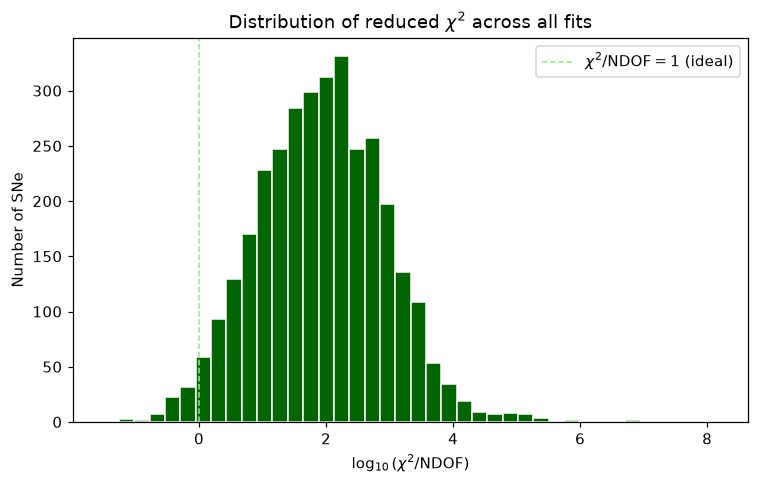

In [23]:
fitres["log_rchi2"] = np.log10(fitres["rchi2"].clip(lower=1e-3))

fig, ax = plt.subplots()
ax.hist(fitres["log_rchi2"], bins=40, color="darkgreen", edgecolor="white")
ax.axvline(0, color="lightgreen", linestyle="--", linewidth=1, label=r"$\chi^2/\mathrm{NDOF}=1$ (ideal)")
ax.set_xlabel(r"$\log_{10}(\chi^2/\mathrm{NDOF})$")
ax.set_ylabel("Number of SNe")
ax.set_title("Distribution of reduced $\chi^2$ across all fits")
ax.legend()
plt.tight_layout()
plt.show()


In [14]:
check_cols = ["NEPOCH", "TRESTMIN", "TRESTMAX", "SNRMAX1", "ZPHOT_FIT", "THETA", "AV", "RV"]
corrs = {
    col: np.corrcoef(fitres["log_rchi2"], fitres[col])[0, 1]
    for col in check_cols if col in fitres.columns
}
pd.Series(corrs, name="corr with log10(rchi2)").sort_values(key=abs, ascending=False)


SNRMAX1      0.283149
AV           0.100261
ZPHOT_FIT    0.079061
RV          -0.065350
NEPOCH       0.058143
TRESTMAX    -0.034475
THETA        0.024884
TRESTMIN     0.024467
Name: corr with log10(rchi2), dtype: float64

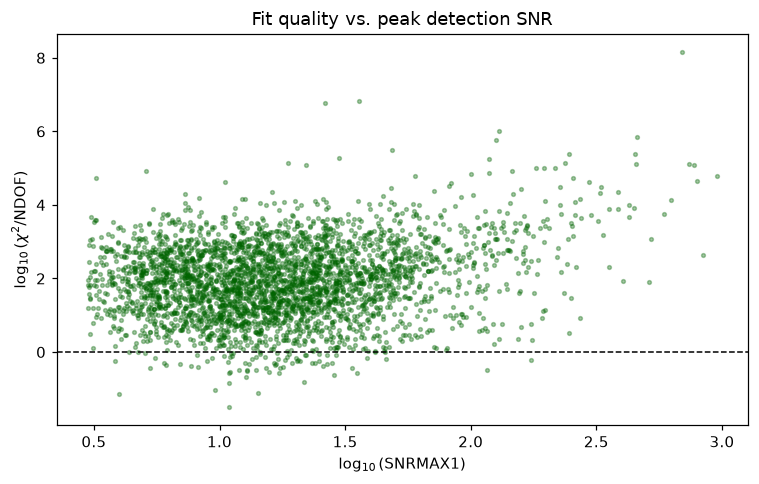

In [24]:
fig, ax = plt.subplots()
ax.scatter(np.log10(fitres["SNRMAX1"].clip(lower=0.1)), fitres["log_rchi2"],
           s=6, alpha=0.35, color="darkgreen")
ax.axhline(0, color="k", linestyle="--", linewidth=1)
ax.set_xlabel(r"$\log_{10}(\mathrm{SNRMAX1})$")
ax.set_ylabel(r"$\log_{10}(\chi^2/\mathrm{NDOF})$")
ax.set_title("Fit quality vs. peak detection SNR")
plt.tight_layout()
plt.show()

In [17]:
cols_show = ["CID", "NEPOCH", "TRESTMAX", "SNRMAX1", "rchi2", "FITPROB"]

print("Worst 10 fits by reduced chi^2:")
display(fitres.sort_values("rchi2", ascending=False)[cols_show].head(10))

print("\nBest 10 fits by FITPROB:")
display(fitres.sort_values("FITPROB", ascending=False)[cols_show].head(10))


Worst 10 fits by reduced chi^2:


,CID,NEPOCH,TRESTMAX,SNRMAX1,rchi2,FITPROB
2680,d173a7a2-a2e6-4c74-837d-d8f9804d5f5b,13,0.7568,692.0313,1.446226e+08,0.0
1210,61340443-efff-47f4-8c4e-6700cdc09f84,12,0.0043,35.8072,6.693517e+06,0.0
2871,dbea9db1-467a-4585-8518-399b7278bb0b,44,73.8535,26.3122,5.889278e+06,0.0
2203,a8f590ea-3e71-4900-af0a-cfe266a15fbf,11,0.6374,129.2871,1.032418e+06,0.0
3201,fa7e6f64-6697-445c-8bf8-a27f193035c4,13,1.3002,460.9168,7.049382e+05,0.0
2480,bd6760c8-3929-40ce-a84f-d7c77e8bc42f,33,1.2911,126.4112,6.008097e+05,0.0
3263,ff89584c-052e-4f4b-82b8-46c38338976d,15,3.3497,48.7648,3.181608e+05,0.0
3216,fa958380-2a21-476d-a83d-cc8b9652691e,11,0.6354,246.4744,2.471001e+05,0.0
179,0a8ea188-f02d-41cd-9fc1-65e979b3c74e,34,7.9827,449.6846,2.352307e+05,0.0
995,4cf44798-0731-479a-819e-7b21cc585b9a,43,2.6820,30.0071,1.943066e+05,0.0



Best 10 fits by FITPROB:


,CID,NEPOCH,TRESTMAX,SNRMAX1,rchi2,FITPROB
1168,5c452f88-76a7-4dc0-9f57-279a38444ddc,9,8.6409,9.5874,0.091591,1.0000
3160,f5797db4-fd2d-474e-9f1f-e09101184dae,12,2.6023,28.6797,0.236824,1.0000
252,0fc1abc1-f824-4fe3-8c00-527a4ed8b698,8,2.6494,14.2849,0.077319,1.0000
2491,c219f6fc-4c34-4d14-99af-e00e87e5549e,8,8.0055,10.8873,0.142362,1.0000
1605,7b056323-eaf0-47fa-86e1-1e86bb40a275,1,-0.0003,3.9909,0.073764,1.0000
2417,b8370d19-80ef-4a70-a301-883e6e3cbe35,3,0.0011,10.9030,0.031650,1.0000
1379,6b91b1be-cd1b-4e7a-98f3-958b434ad79d,7,7.3239,21.7225,0.155625,1.0000
3125,f08f3df1-ff94-4132-9541-7a9145fc3d9b,6,-0.0002,12.7383,0.202732,0.9999
1607,7b061263-14d2-469f-b783-0ad87df17c01,12,1.3250,10.9480,0.270972,0.9999
2729,d1c6978e-283c-42e2-9879-e63d3de4d5c1,8,9.9650,17.1837,0.270152,0.9996


In [18]:
fit_summary = pd.read_csv(SUMMARY_PATH, index_col=0)
fit_summary.index.name = "param"
print(f"{len(fit_summary)} parameter rows")
fit_summary.head()


195467 parameter rows


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
param,,,,,,,,,
AV[0],0.029,0.028,0.000,0.081,0.001,0.001,651.0,349.0,1.01
AV[1],0.111,0.114,0.000,0.334,0.023,0.017,13.0,388.0,1.24
AV[2],0.181,0.175,0.001,0.487,0.005,0.004,725.0,524.0,1.00
AV[3],0.234,0.176,0.000,0.530,0.008,0.006,308.0,470.0,1.02
AV[4],0.180,0.176,0.002,0.489,0.005,0.004,844.0,509.0,1.00


In [19]:
print("R-hat summary across ALL parameters in the run:")
print(fit_summary["r_hat"].describe())
print()
print(f"Fraction with R-hat > 1.01 : {(fit_summary['r_hat'] > 1.01).mean():.1%}")
print(f"Fraction with R-hat > 1.1  : {(fit_summary['r_hat'] > 1.1).mean():.1%}")
print()
print("Bulk ESS summary:")
print(fit_summary["ess_bulk"].describe())

R-hat summary across ALL parameters in the run:
count    192154.000000
mean          1.096570
std           0.281749
min           1.000000
25%           1.000000
50%           1.010000
75%           1.010000
max           4.570000
Name: r_hat, dtype: float64

Fraction with R-hat > 1.01 : 23.2%
Fraction with R-hat > 1.1  : 14.0%

Bulk ESS summary:
count    195467.000000
mean       1021.747763
std         584.533358
min           4.000000
25%         719.000000
50%        1148.000000
75%        1412.000000
max        3000.000000
Name: ess_bulk, dtype: float64


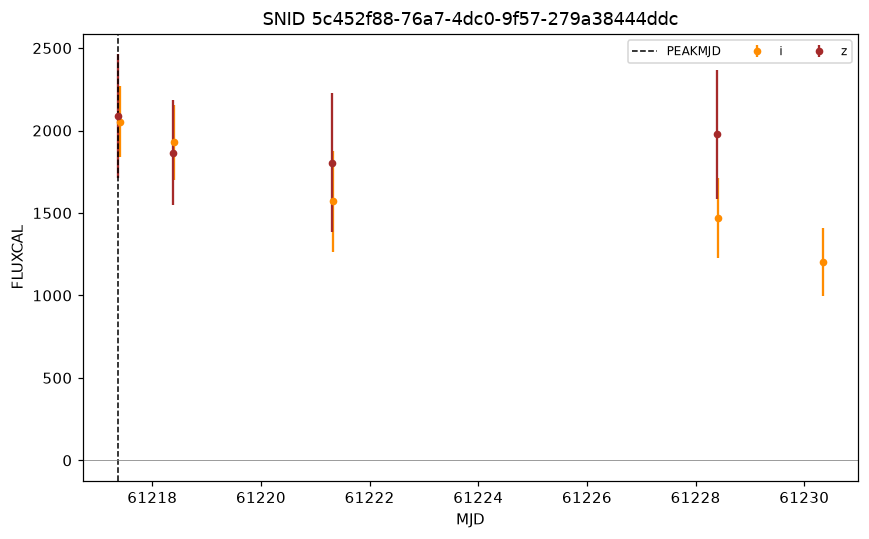

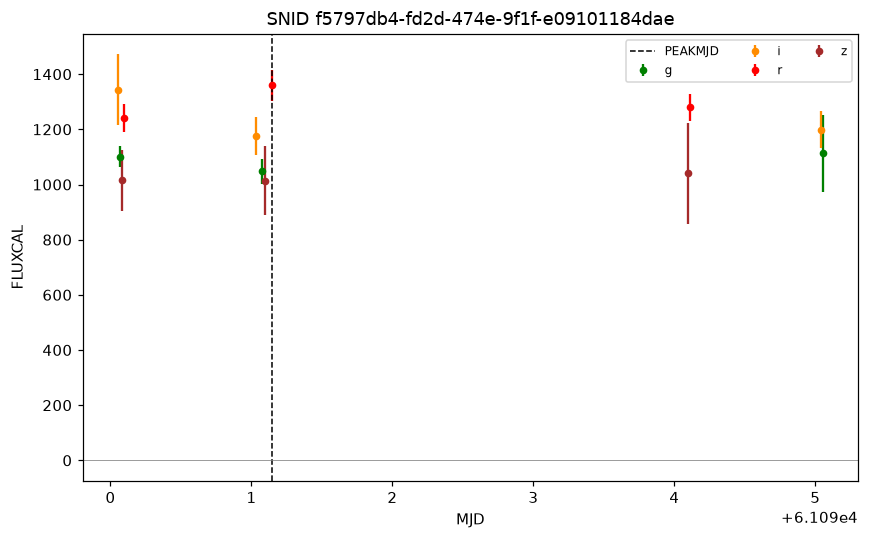

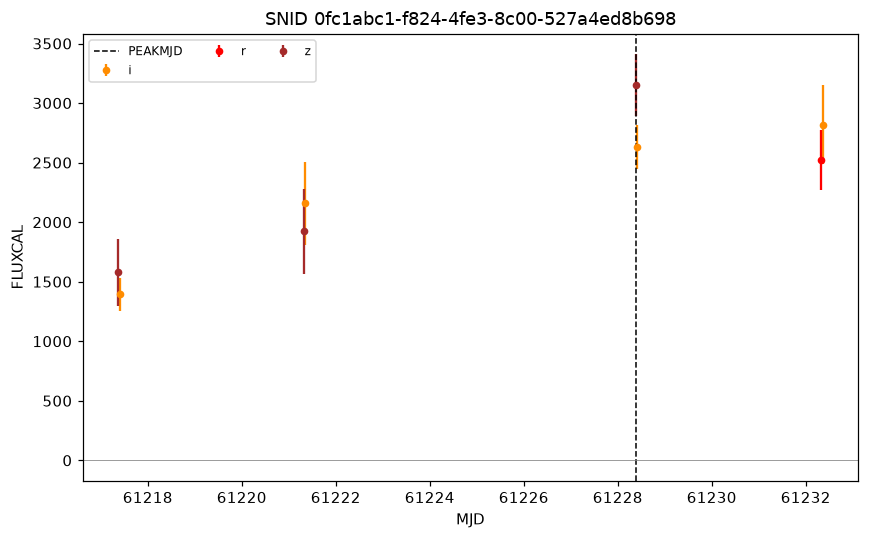

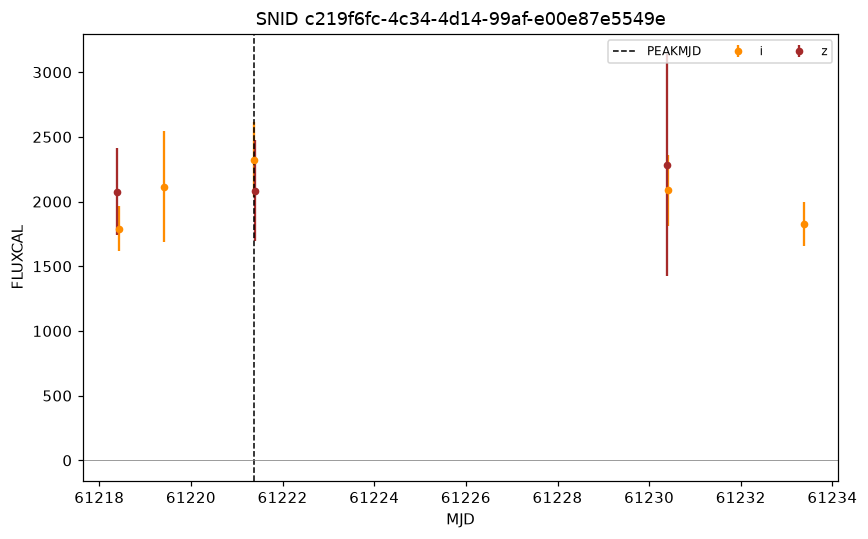

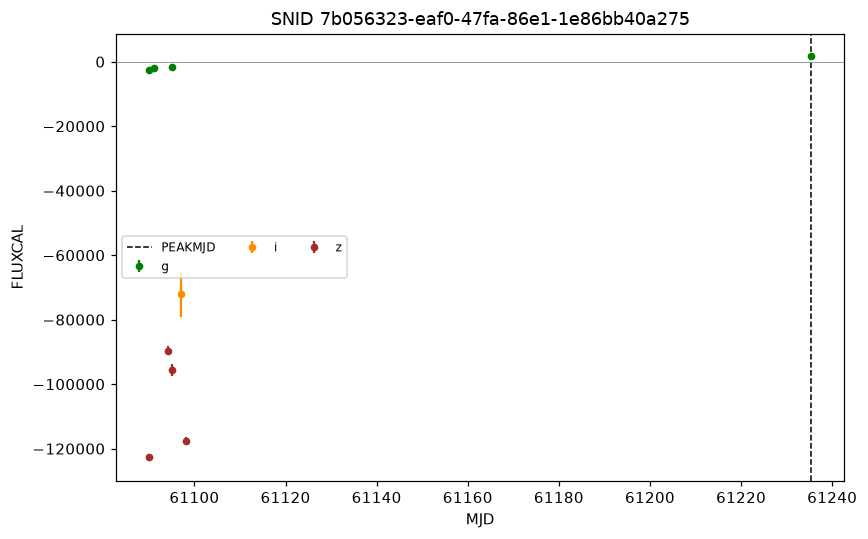

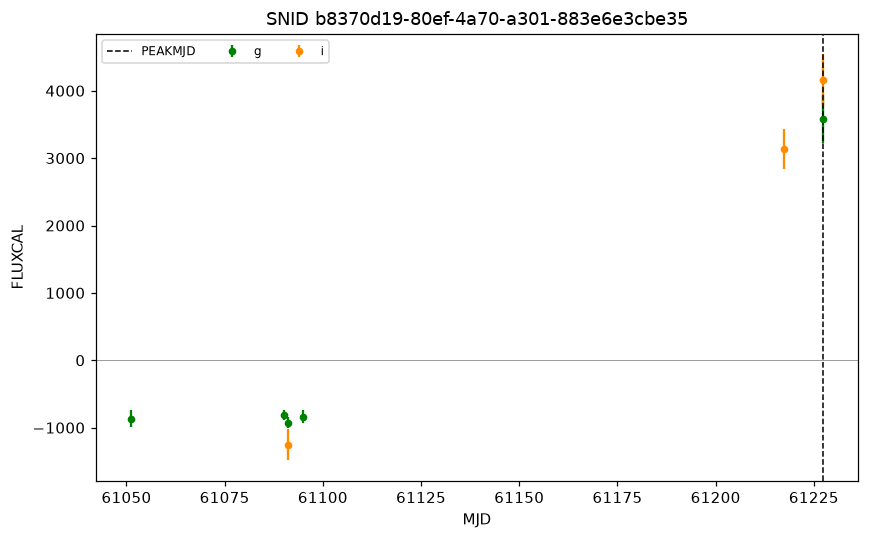

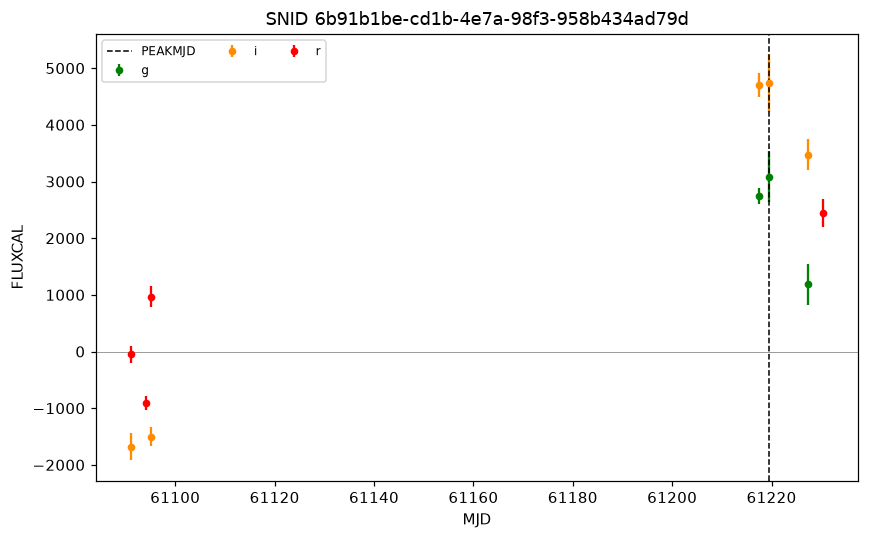

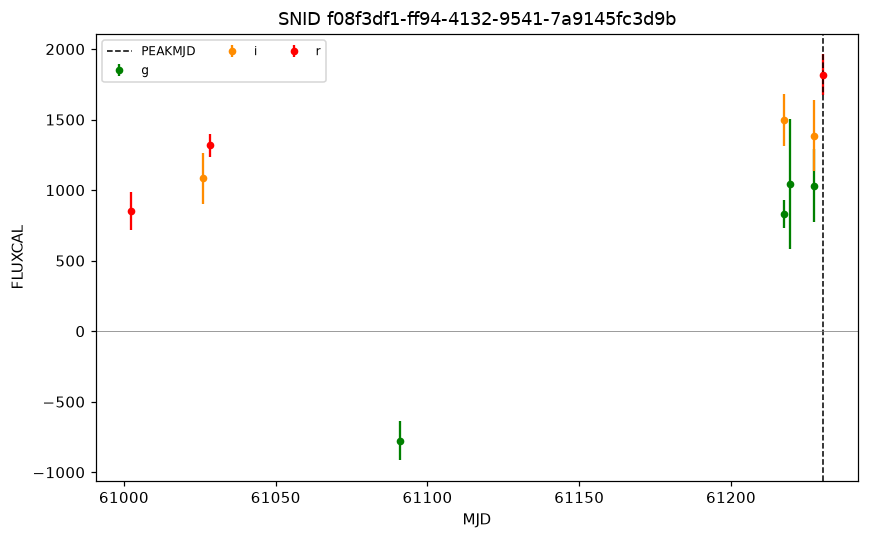

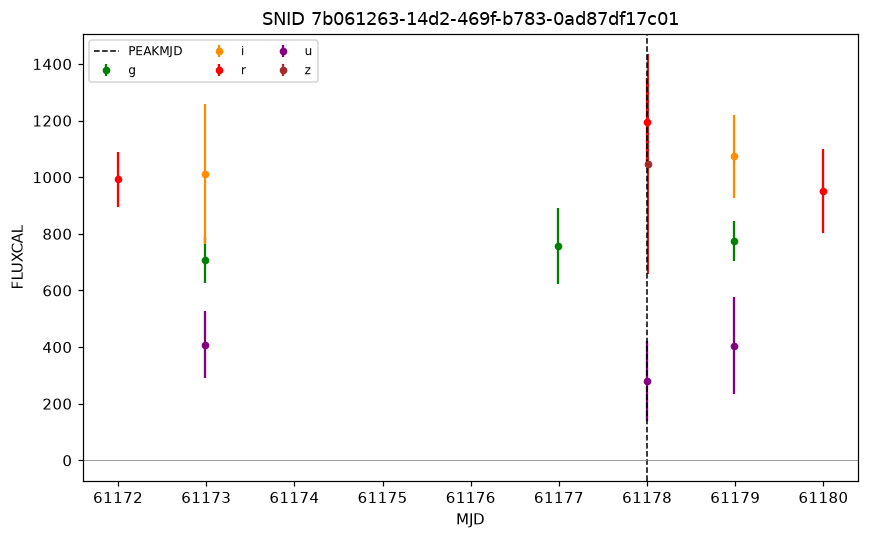

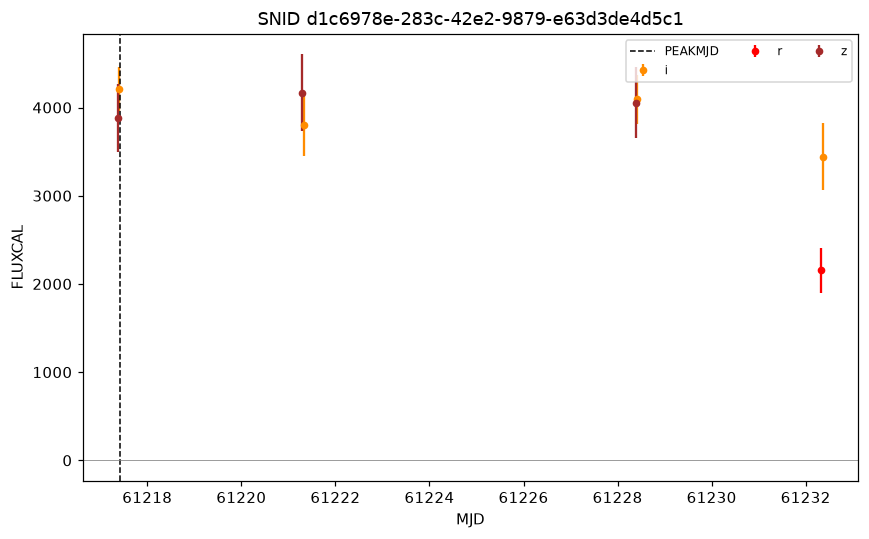

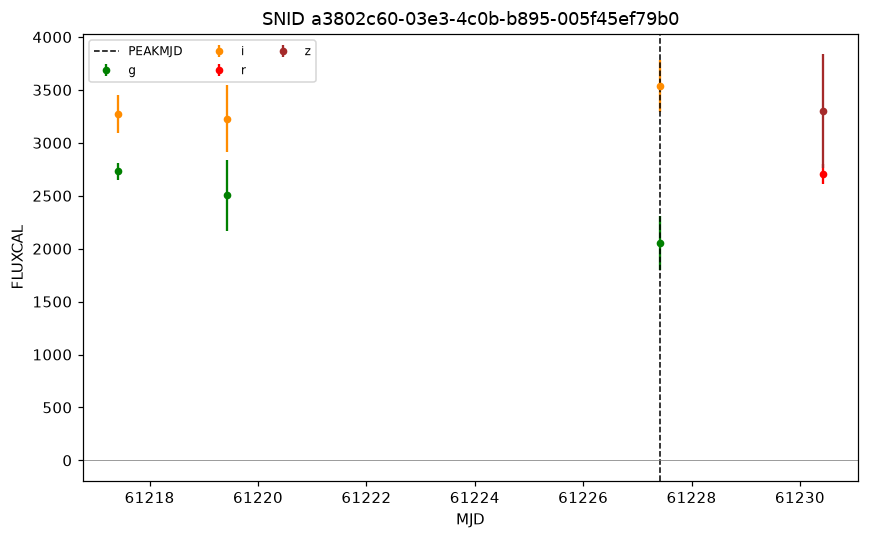

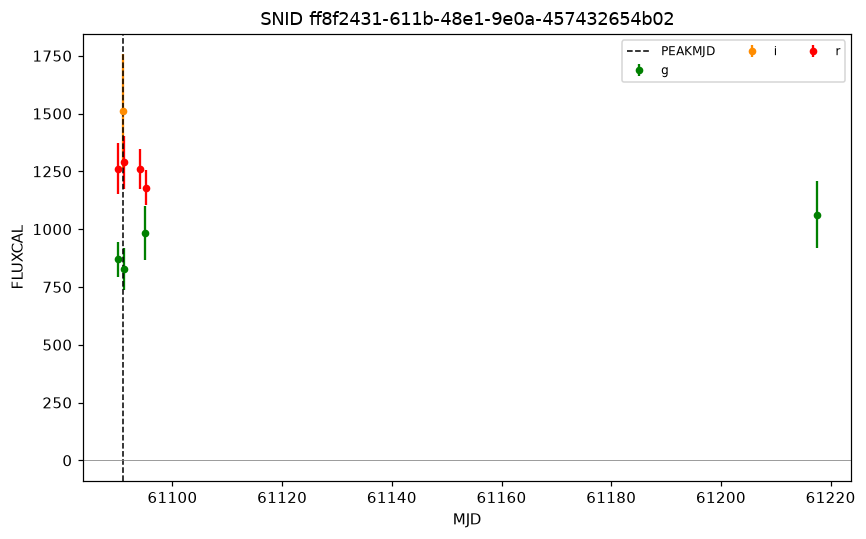

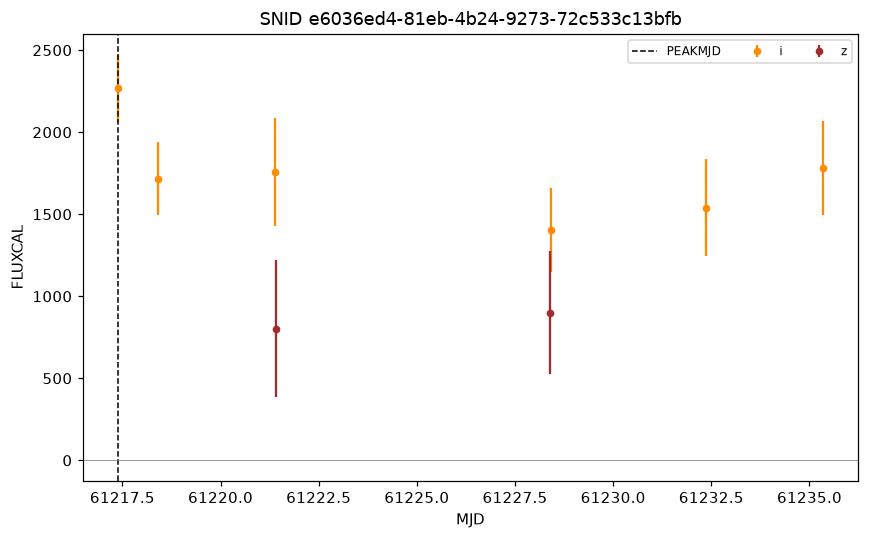

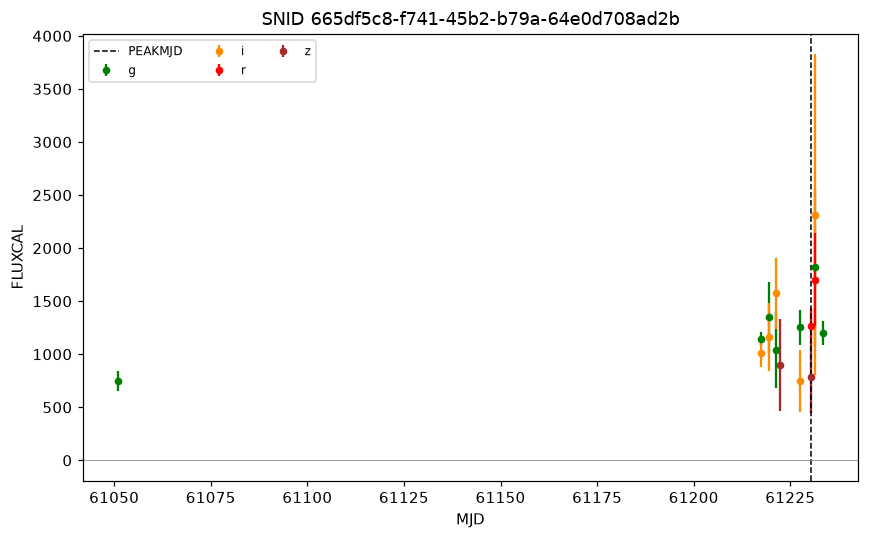

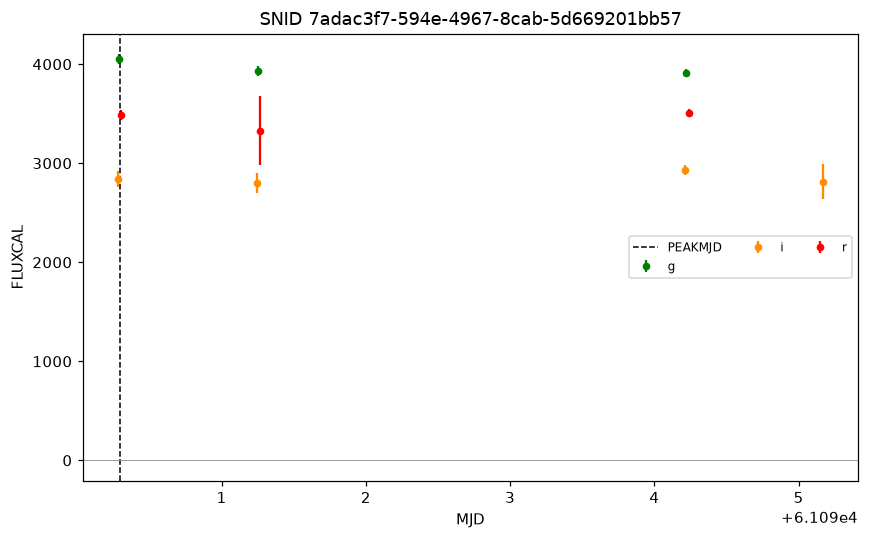

In [30]:
import glob
from pathlib import Path
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt

PHOT_DIR = Path("../data/LSST_ALERTS/LSST") 

FILTER_MAP = config["map"]  # e.g. {'u':'u_LSST', 'g':'g_LSST', ...} from input.yaml
BAND_COLORS = {'u':'purple','g':'g','r':'r','i':'darkorange','z':'brown','y':'k'}

def find_snid(snid, phot_dir=PHOT_DIR):
    """Search every *_HEAD.FITS(.gz) split file for `snid`, return (head_row, phot_table)."""
    snid = str(snid).strip()
    for head_path in sorted(Path(phot_dir).glob("*_HEAD.FITS.gz")):
        with fits.open(head_path) as hdul:
            head = hdul[1].data
            ids = np.char.strip(head['SNID'].astype(str))
            match = np.where(ids == snid)[0]
            if len(match):
                i = match[0]
                phot_path = str(head_path).replace("_HEAD.FITS.gz", "_PHOT.FITS.gz")
                ptr_min, ptr_max = int(head['PTROBS_MIN'][i]), int(head['PTROBS_MAX'][i])
                with fits.open(phot_path) as phdul:
                    phot = phdul[1].data[ptr_min - 1 : ptr_max]
                return head[i], phot
    raise ValueError(f"SNID {snid} not found under {phot_dir}")

def plot_lightcurve(snid, ax=None):
    head_row, phot = find_snid(snid)
    if ax is None:
        fig, ax = plt.subplots()
    for band in np.unique(np.char.strip(phot['BAND'].astype(str))):
        m = (np.char.strip(phot['BAND'].astype(str)) == band) & (phot['MJD'] > 0)
        ax.errorbar(phot['MJD'][m], phot['FLUXCAL'][m], yerr=phot['FLUXCALERR'][m],
                     fmt='o', ms=4, color=BAND_COLORS.get(band, None), label=band)
    try:
        ax.axvline(head_row['PEAKMJD'], ls='--', c='k', lw=1, label='PEAKMJD')
    except Exception:
        pass
    ax.axhline(0, c='gray', lw=0.5)
    ax.set_xlabel('MJD'); ax.set_ylabel('FLUXCAL')
    ax.set_title(f'SNID {snid}')
    ax.legend(fontsize=8, ncol=3)
    return head_row, phot
    
# Plot the best fits by FITPROB, e.g. top 6 from `fitres`
best_cids = fitres.sort_values('FITPROB', ascending=False)['CID'].head(15).tolist()

for cid in best_cids:
    fig, ax = plt.subplots(figsize=(8, 5))
    try:
        plot_lightcurve(cid, ax=ax)
    except ValueError as e:
        ax.set_title(f"{cid}: not found")
        print(e)
    plt.tight_layout()
    plt.show()

In [26]:
from pathlib import Path

PHOT_DIR = Path("../data/LSST_ALERTS/LSST")

print("PHOT_DIR resolves to:", PHOT_DIR.resolve())
print("exists:", PHOT_DIR.exists())
print()
print("Top-level contents:")
for p in sorted(PHOT_DIR.iterdir())[:20]:
    print(" ", p)
print()
print("Non-recursive glob *_HEAD.FITS:", len(list(PHOT_DIR.glob("*_HEAD.FITS"))))
print("Recursive glob **/*_HEAD.FITS :", len(list(PHOT_DIR.rglob("*_HEAD.FITS"))))

PHOT_DIR resolves to: /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/data/LSST_ALERTS/LSST
exists: True

Top-level contents:
  ../data/LSST_ALERTS/LSST/LSST.IGNORE
  ../data/LSST_ALERTS/LSST/LSST.LIST
  ../data/LSST_ALERTS/LSST/LSST.README
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT001_HEAD.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT001_PHOT.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT002_HEAD.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT002_PHOT.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT003_HEAD.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT003_PHOT.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT004_HEAD.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT004_PHOT.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT005_HEAD.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT005_PHOT.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT006_HEAD.FITS.gz
  ../data/LSST_ALERTS/LSST/LSST_CHUNK01_SPLIT006_PHOT.FITS.gz
 

In [28]:
head_row, phot = find_snid(best_cids[0])
print(phot.columns.names)

['MJD', 'BAND', 'DETNUM', 'IMGNUM', 'FIELD', 'PHOTFLAG', 'PHOTPROB', 'FLUXCAL', 'FLUXCALERR', 'PSF_SIG1', 'PSF_SIG2', 'PSF_RATIO', 'SKY_SIG', 'SKY_SIG_T', 'RDNOISE', 'ZEROPT', 'ZEROPT_ERR', 'TEXPOSE', 'GAIN', 'XPIX', 'YPIX']


In [33]:
theta_rows_rhat = fit_summary[fit_summary.index.str.match(r"^theta\[\d+\]$")].copy()
theta_rows_rhat["idx"] = theta_rows_rhat.index.str.extract(r"\[(\d+)\]").astype(int)[0]
theta_rows_rhat = theta_rows_rhat.sort_values("idx").reset_index(drop=True)

fitres_merged = fitres.reset_index(drop=True).copy()
fitres_merged["theta_rhat"] = theta_rows_rhat["r_hat"].values
fitres_merged["theta_ess"] = theta_rows_rhat["ess_bulk"].values

In [34]:
theta_rows = fit_summary[fit_summary.index.str.match(r"^theta\[\d+\]$")].copy()
theta_rows["idx"] = theta_rows.index.str.extract(r"\[(\d+)\]").astype(int)[0]
theta_rows = theta_rows.sort_values("idx").reset_index(drop=True)
theta_rows["theta_hdi_width"] = theta_rows["hdi_97%"] - theta_rows["hdi_3%"]  # adjust col names to your actual fit_summary header

rank_df = fitres_merged.copy()
rank_df["theta_hdi_width"] = theta_rows["theta_hdi_width"].values

# crude composite: converged, well-constrained, decent chi2, decent phase coverage
rank_df["ia_score"] = (
    (rank_df["theta_rhat"] < 1.01).astype(int)
    + (rank_df["theta_hdi_width"] < rank_df["theta_hdi_width"].median()).astype(int)
    + (rank_df["NEPOCH"] >= 10).astype(int)
    + ((rank_df["TRESTMAX"] - rank_df["TRESTMIN"]) > 10).astype(int)
    + (rank_df["FITPROB"] > 0.001).astype(int)
)

rank_df.sort_values(["ia_score", "FITPROB"], ascending=False).head(20)

,CID,IDSURVEY,TYPE,FIELD,zHEL,zHELERR,zHD,zHDERR,VPEC,VPECERR,...,ZPHOT_FITERR,FITCHI2,NDOF,FITPROB,rchi2,log_rchi2,theta_rhat,theta_ess,theta_hdi_width,ia_score
740,38733078-e3b2-4817-9a86-64cae48a35fb,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0155,30.6127,46,0.9606,0.665493,-0.176856,1.00,750.0,1.336,5
327,197705de-ef55-4fad-9cfb-4553e23dfc9f,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0307,13.7266,24,0.9526,0.571942,-0.242648,1.00,572.0,2.707,5
2923,e10f7cbf-0d69-4b89-a2c1-7f91864a7fdb,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0599,19.2460,27,0.8609,0.712815,-0.147023,1.00,847.0,3.202,5
1679,84ccc74d-d7e3-4144-9d6b-11b4ff401275,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0602,25.6921,29,0.6419,0.885934,-0.052598,1.00,472.0,3.003,5
2206,a90065f9-bfa1-4cb3-a8be-79dbfcacdc6a,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0188,39.9826,29,0.0842,1.378710,0.139473,1.00,762.0,2.017,5
2361,b3428a9a-e072-48f0-b2ed-9e6f7a2be1c1,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0161,48.7980,35,0.0607,1.394229,0.144334,1.00,602.0,1.309,5
707,3389b047-0124-4d13-b722-8ac774c13604,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0176,39.2195,26,0.0464,1.508442,0.178529,1.00,470.0,3.373,5
1017,51d83a3d-f3e4-4003-9ea9-835ee6d5f1e0,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0276,44.3200,23,0.0048,1.926957,0.284872,1.00,544.0,2.018,5
3240,fab2f76b-bc2b-4adb-a50e-6f07cd1ec607,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0133,51.7279,27,0.0029,1.915848,0.282361,1.00,396.0,1.341,5
1290,665df5c8-f741-45b2-b79a-64e0d708ad2b,0,0,VOID,-999.0,-9.0,-999.0,-9.0,0.0,300.0,...,0.0730,9.9800,28,0.9993,0.356429,-0.448027,1.01,610.0,3.335,4


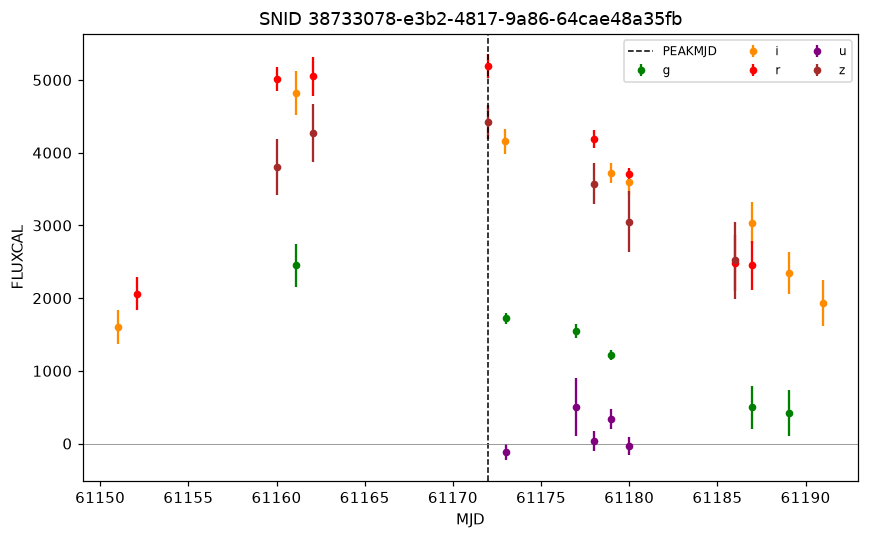

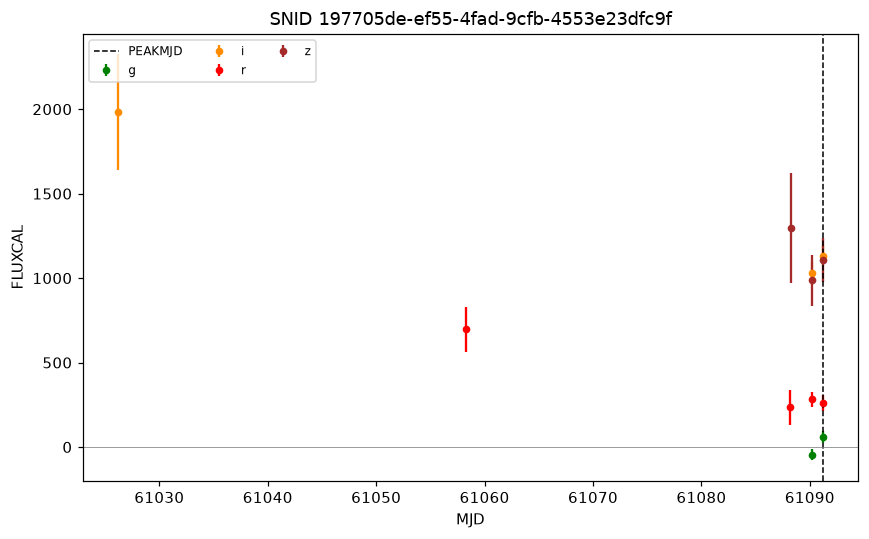

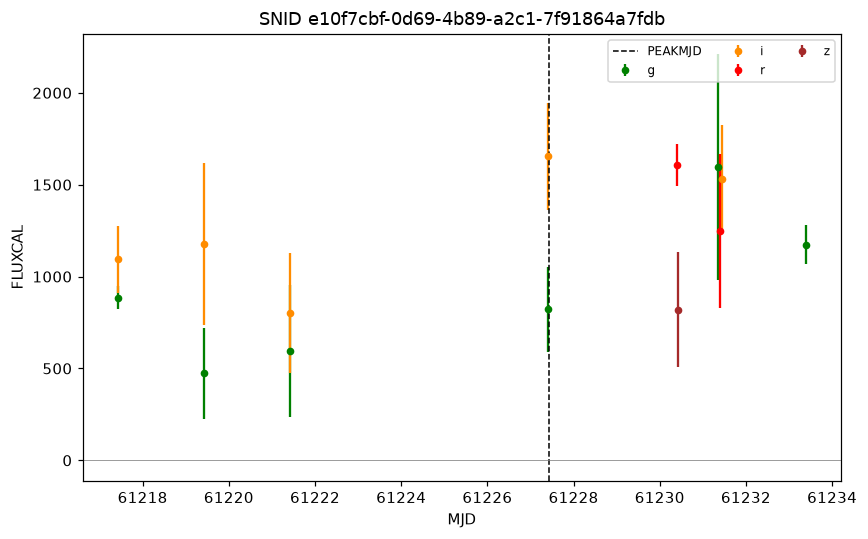

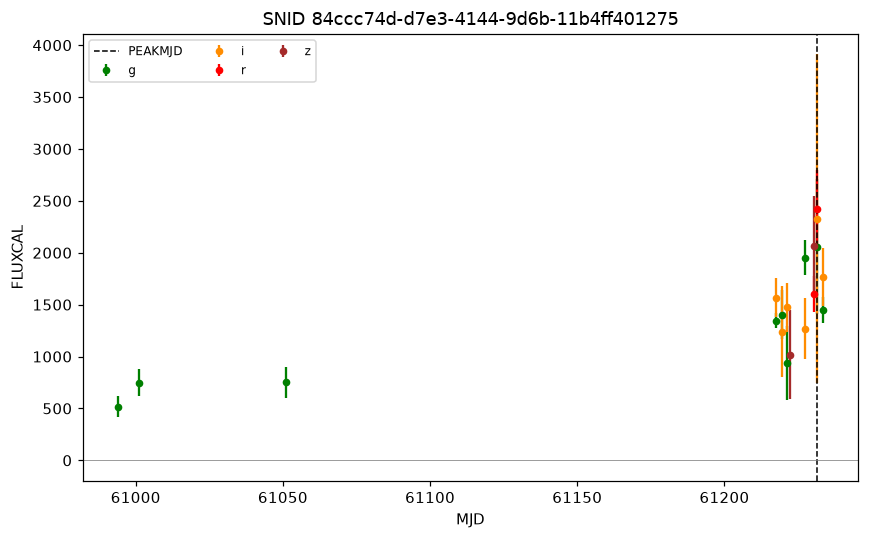

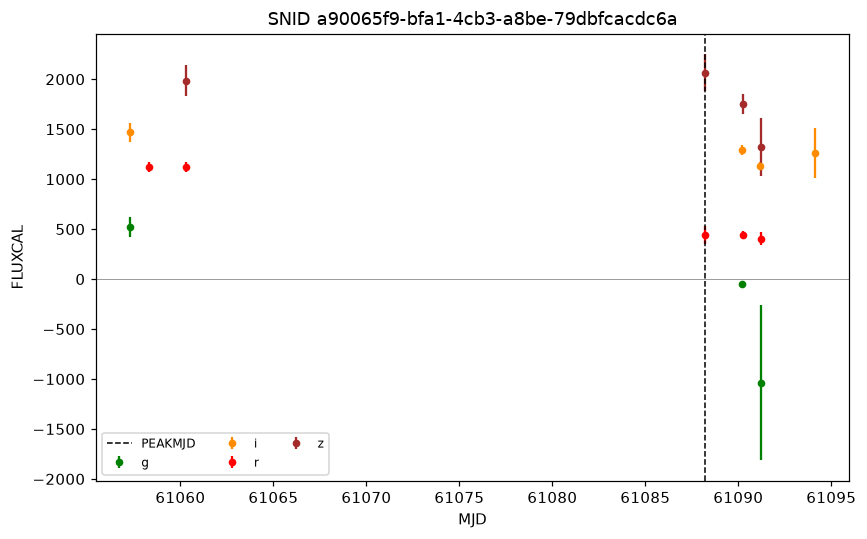

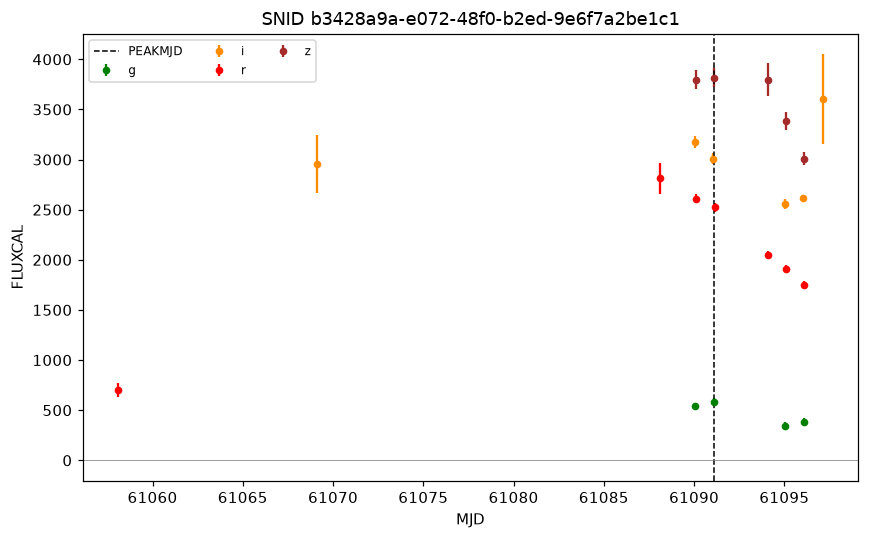

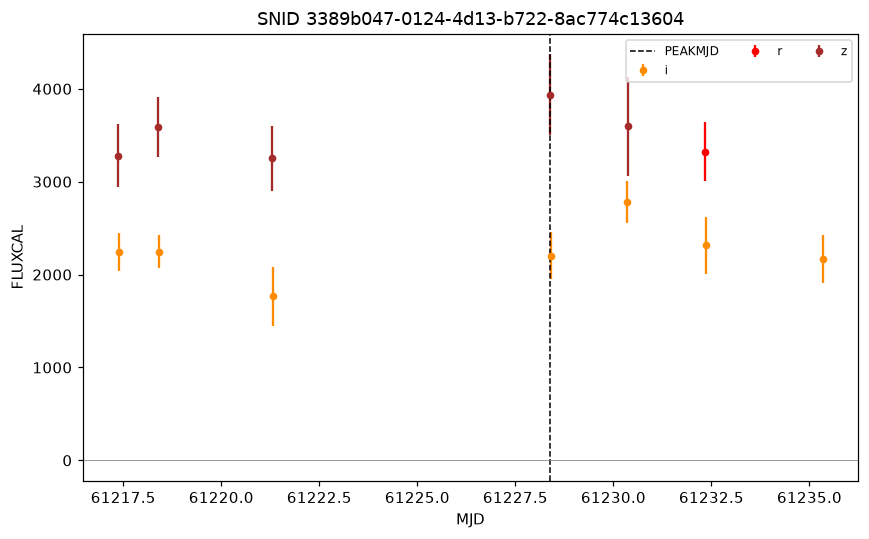

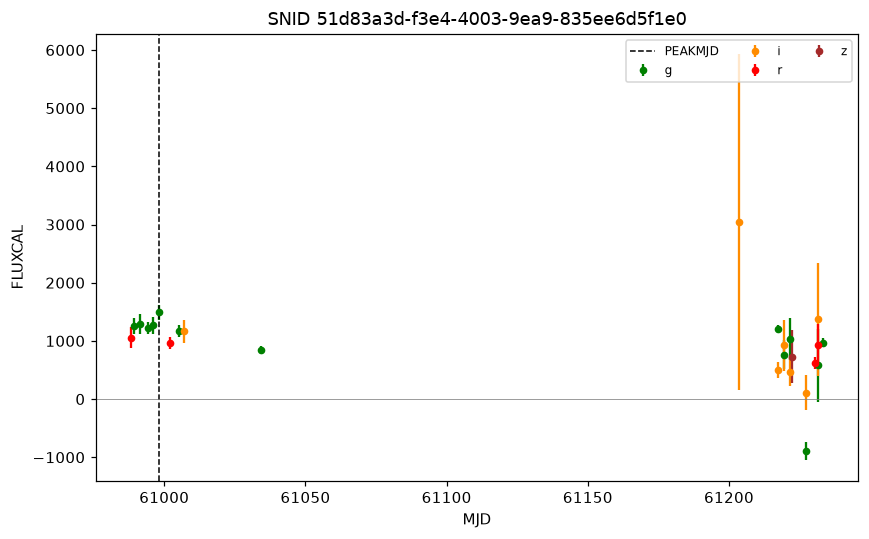

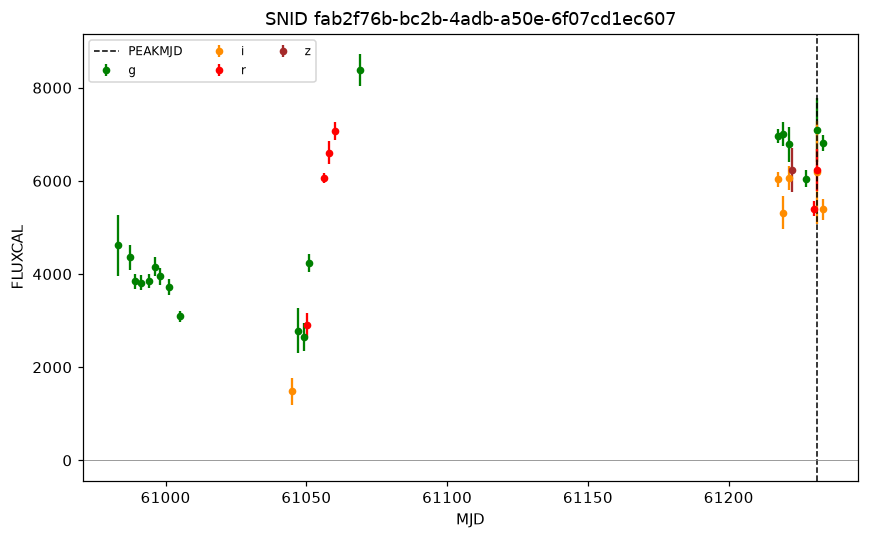

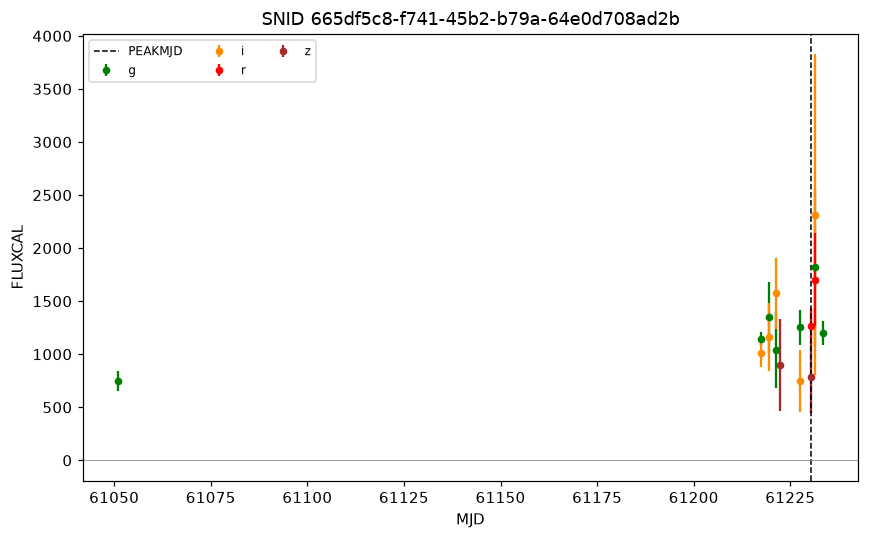

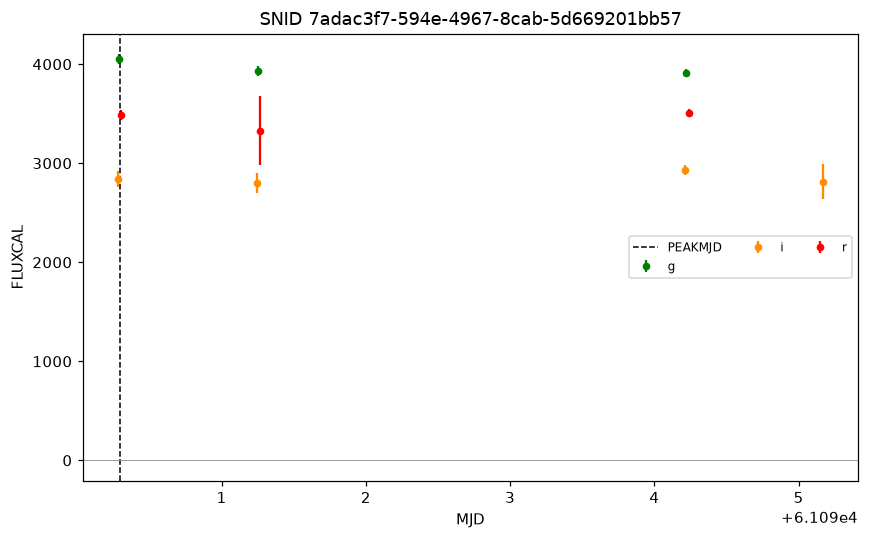

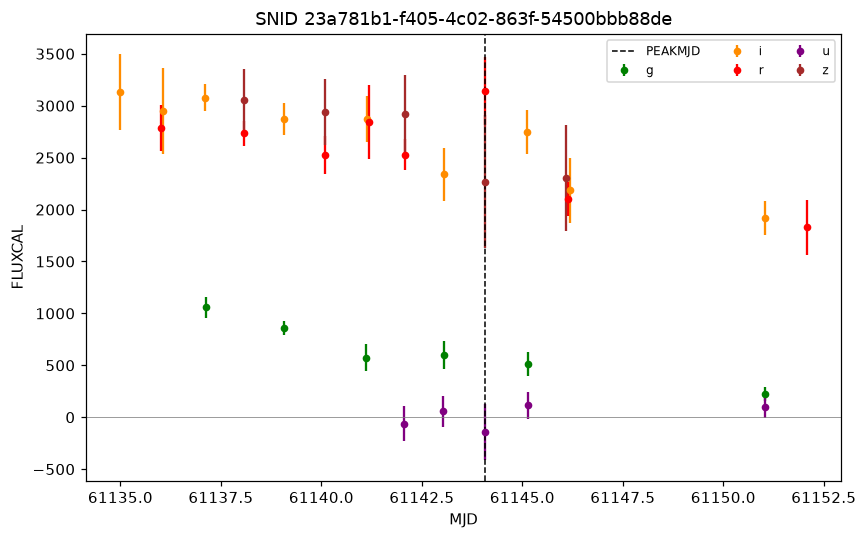

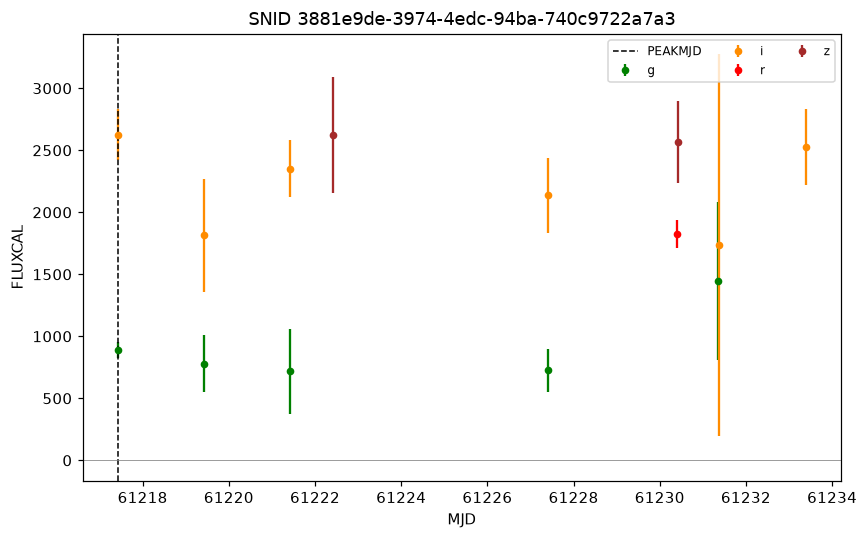

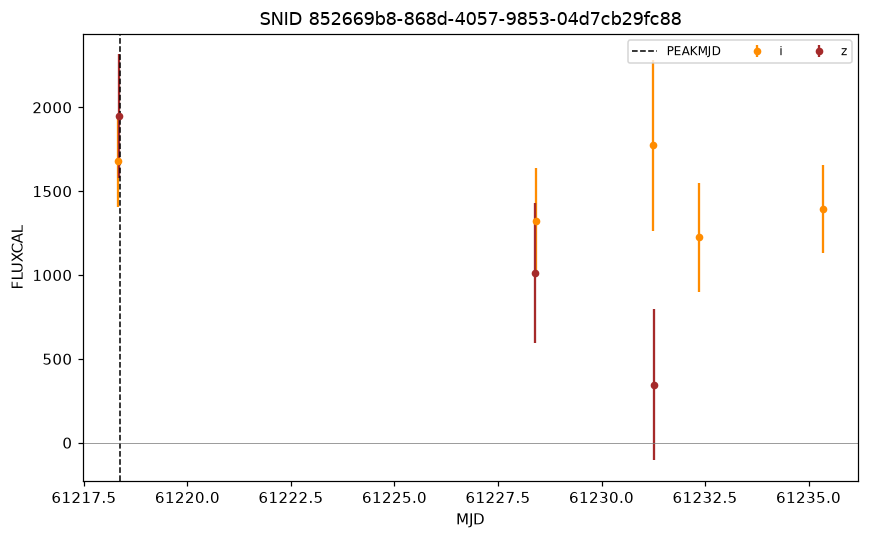

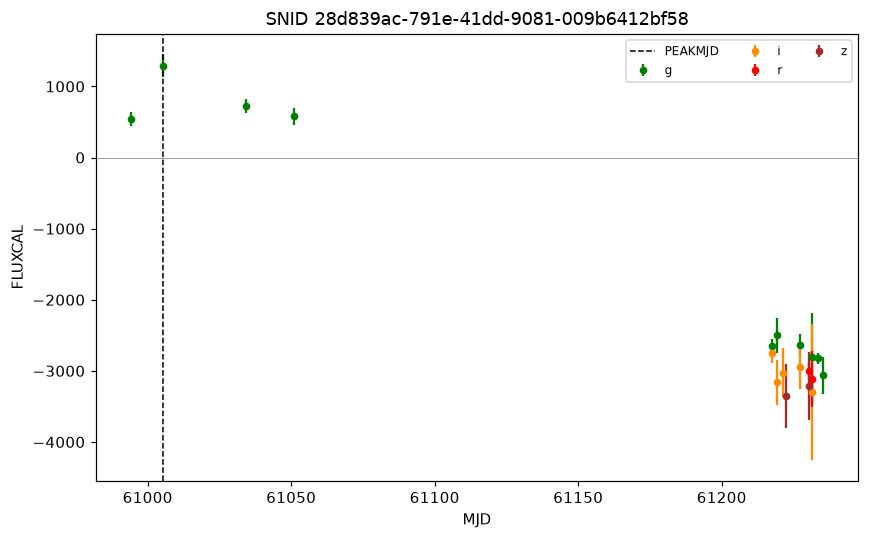

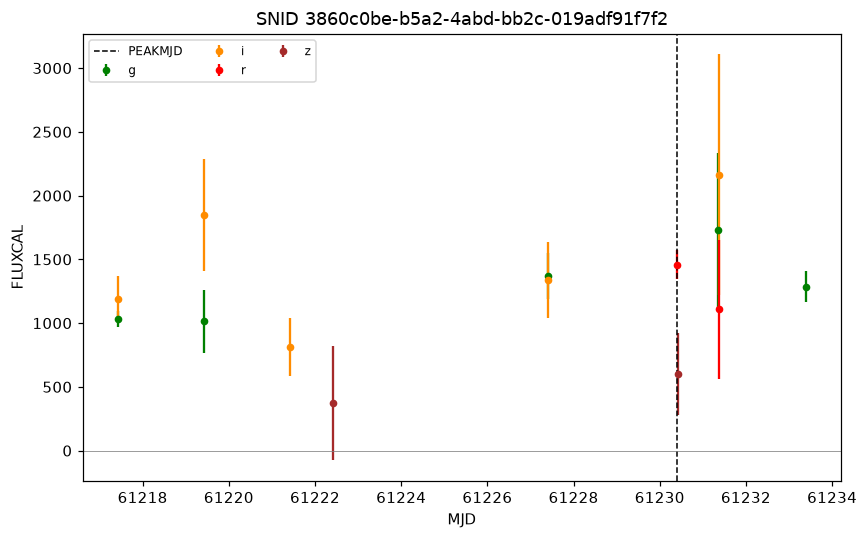

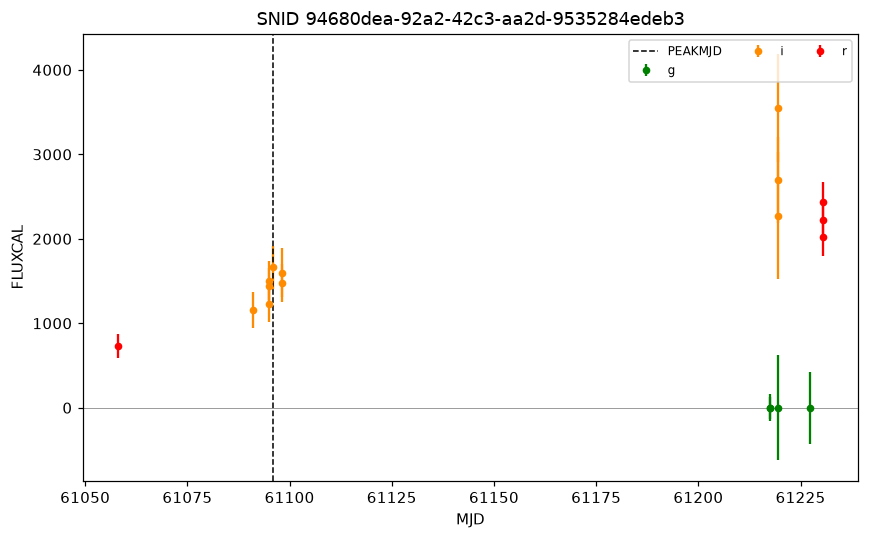

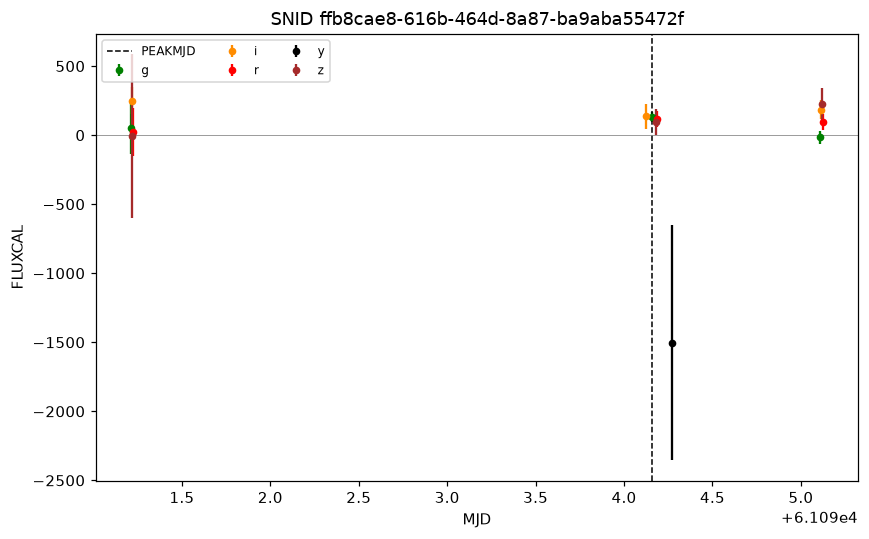

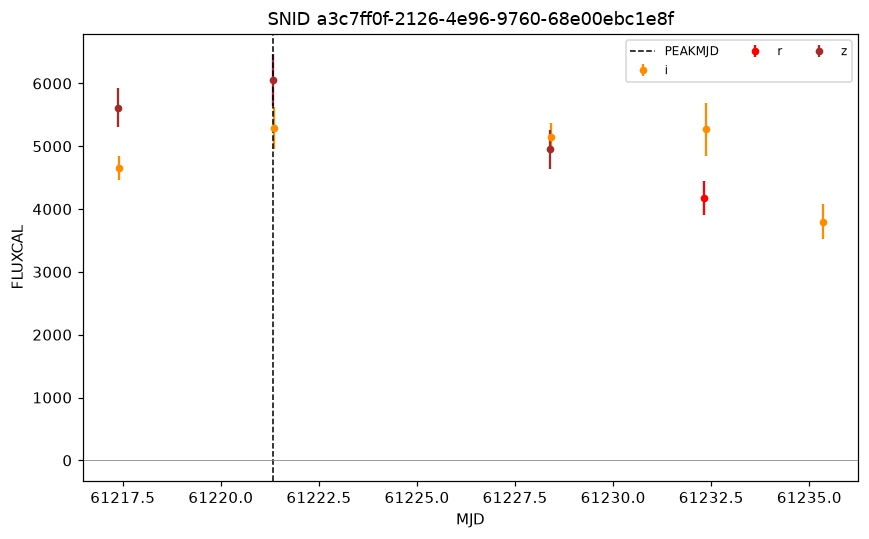

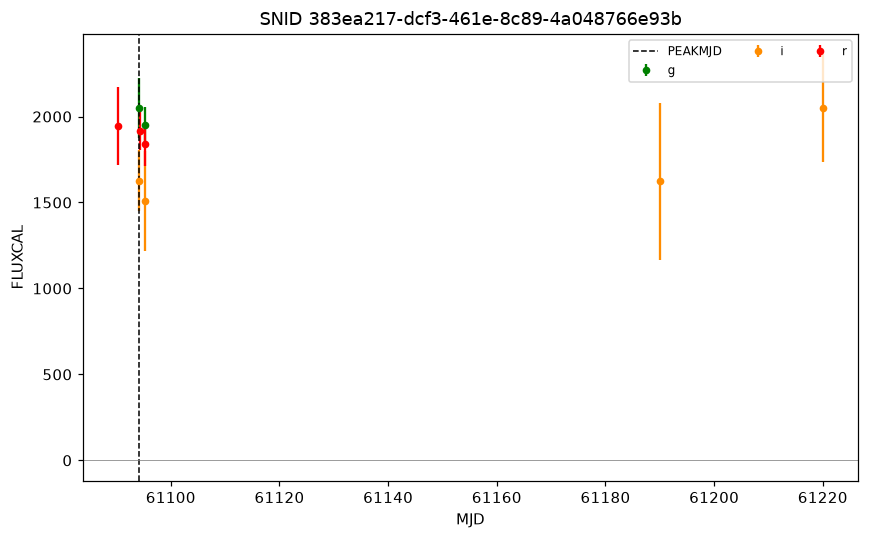

In [36]:
top_cids = rank_df.sort_values(["ia_score", "FITPROB"], ascending=False)["CID"].head(20).tolist()
for cid in top_cids:
    fig, ax = plt.subplots(figsize=(8, 5))
    try:
        plot_lightcurve(cid, ax=ax)
    except ValueError as e:
        print(e)
    plt.tight_layout()
    plt.show()

In [37]:
rank_df["ia_score"].value_counts().sort_index(ascending=False)

ia_score
5       9
4     363
3    1002
2    1190
1     624
0     125
Name: count, dtype: int64

In [38]:
def compute_max_gaps(phot_dir, snids_of_interest=None):
    """Return {SNID: max gap in days between consecutive photometry epochs}."""
    results = {}
    for head_path in sorted(Path(phot_dir).glob("*_HEAD.FITS.gz")):
        phot_path = str(head_path).replace("_HEAD.FITS.gz", "_PHOT.FITS.gz")
        with fits.open(head_path) as hhdul, fits.open(phot_path) as phdul:
            head = hhdul[1].data
            phot_all = phdul[1].data
            ids = np.char.strip(head['SNID'].astype(str))
            for i, sid in enumerate(ids):
                if snids_of_interest is not None and sid not in snids_of_interest:
                    continue
                ptr_min, ptr_max = int(head['PTROBS_MIN'][i]), int(head['PTROBS_MAX'][i])
                mjd = phot_all['MJD'][ptr_min - 1 : ptr_max]
                mjd = np.sort(mjd[mjd > 0])  # drop -777 terminator / padding rows
                results[sid] = np.max(np.diff(mjd)) if len(mjd) >= 2 else np.nan
    return results

snid_set = set(rank_df['CID'])
gap_map = compute_max_gaps(PHOT_DIR, snids_of_interest=snid_set)
rank_df['max_gap_days'] = rank_df['CID'].map(gap_map)

In [39]:
rank_df_clean = rank_df[rank_df['max_gap_days'] <= 100].copy()
print(f"kept {len(rank_df_clean)} / {len(rank_df)} ({len(rank_df_clean)/len(rank_df):.1%})")

kept 2749 / 3313 (83.0%)


ia_score = 
    (theta_rhat < 1.01)                        # did the sampler converge?
  + (theta_hdi_width < median)                  # is theta well-constrained, not just "converged to a shrug"?
  + (NEPOCH >= 10)                              # is there enough photometry at all?
  + (TRESTMAX - TRESTMIN > 10)                  # does it span enough phase to see a rise/decline?
  + (FITPROB > 0.001)                           # is the χ² not catastrophic?
  + (max_gap_days <= 100)                       # is it one continuous event, not stitched-together seasons?

In [40]:
rank_df["ia_score"] = (
    (rank_df["theta_rhat"] < 1.01).astype(int)
    + (rank_df["theta_hdi_width"] < rank_df["theta_hdi_width"].median()).astype(int)
    + (rank_df["NEPOCH"] >= 10).astype(int)
    + ((rank_df["TRESTMAX"] - rank_df["TRESTMIN"]) > 10).astype(int)
    + (rank_df["FITPROB"] > 0.001).astype(int)
    + (rank_df["max_gap_days"] <= 100).astype(int)
)

<Axes: >

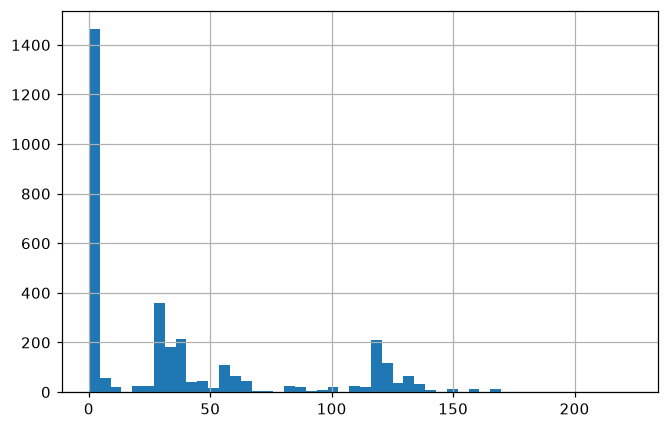

In [41]:
rank_df['max_gap_days'].describe()
rank_df['max_gap_days'].hist(bins=50)

In [42]:
GAP_THRESHOLD = 100

rank_df["ia_score"] = (
    (rank_df["theta_rhat"] < 1.01).astype(int)
    + (rank_df["theta_hdi_width"] < rank_df["theta_hdi_width"].median()).astype(int)
    + (rank_df["NEPOCH"] >= 10).astype(int)
    + ((rank_df["TRESTMAX"] - rank_df["TRESTMIN"]) > 10).astype(int)
    + (rank_df["FITPROB"] > 0.001).astype(int)
    + (rank_df["max_gap_days"] <= GAP_THRESHOLD).astype(int)
)

rank_df_clean = rank_df[rank_df["max_gap_days"] <= GAP_THRESHOLD].copy()
print(f"kept {len(rank_df_clean)} / {len(rank_df)} ({len(rank_df_clean)/len(rank_df):.1%})")
print(rank_df_clean["ia_score"].value_counts().sort_index(ascending=False))

kept 2749 / 3313 (83.0%)
ia_score
6      6
5    277
4    815
3    994
2    540
1    117
Name: count, dtype: int64


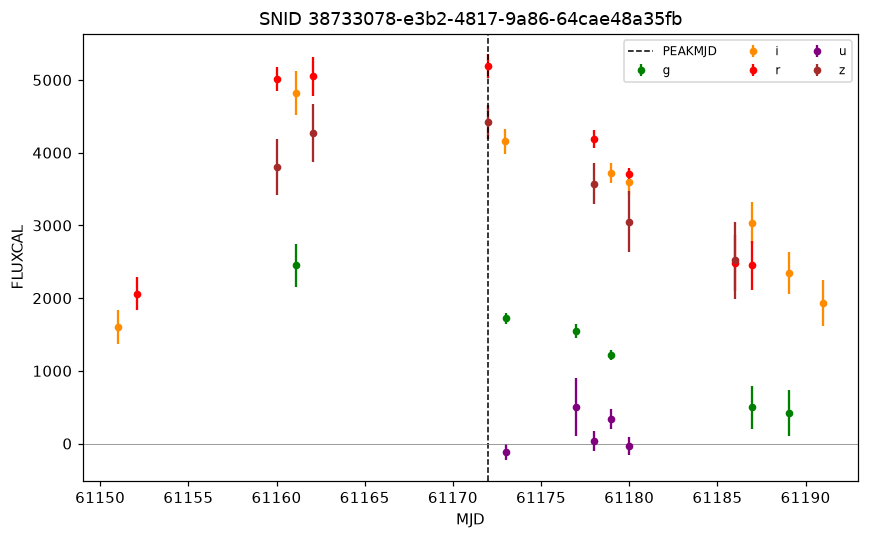

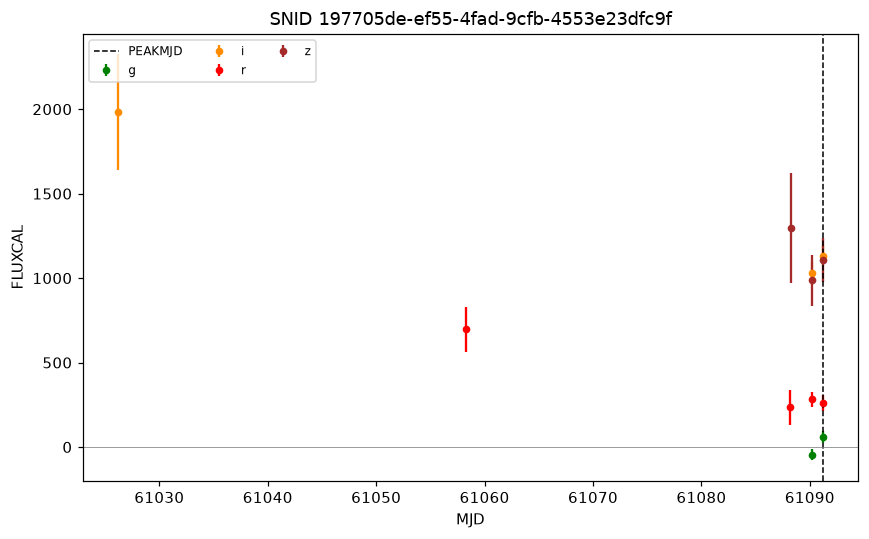

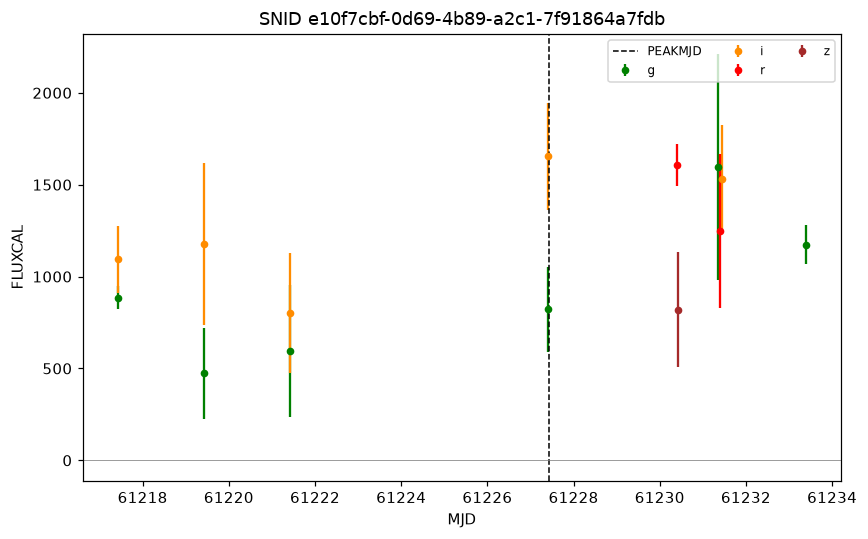

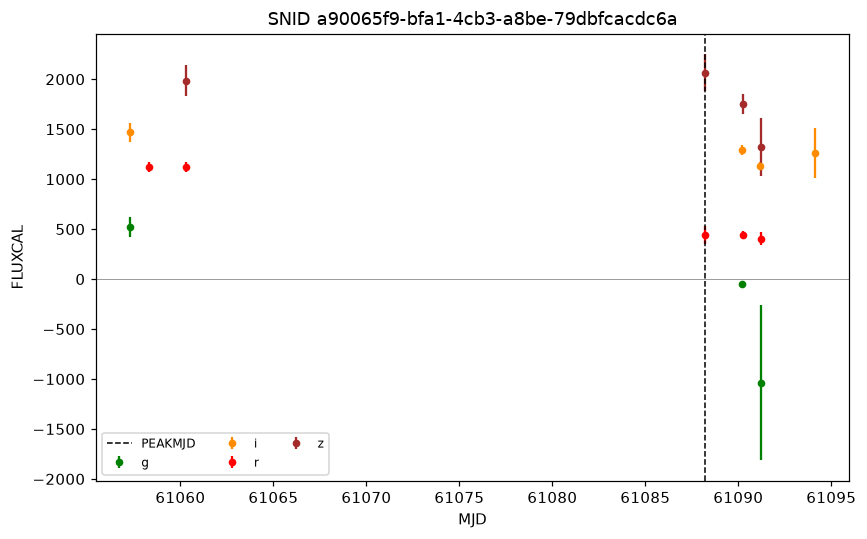

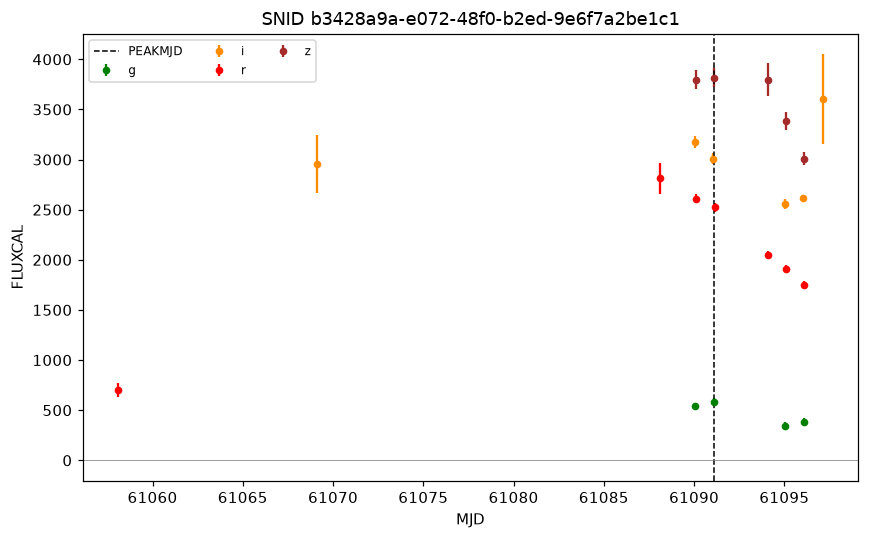

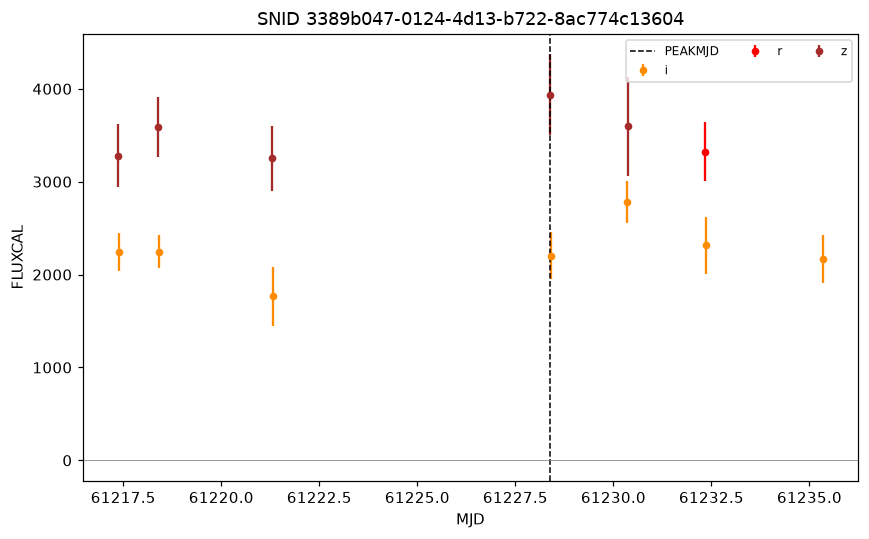

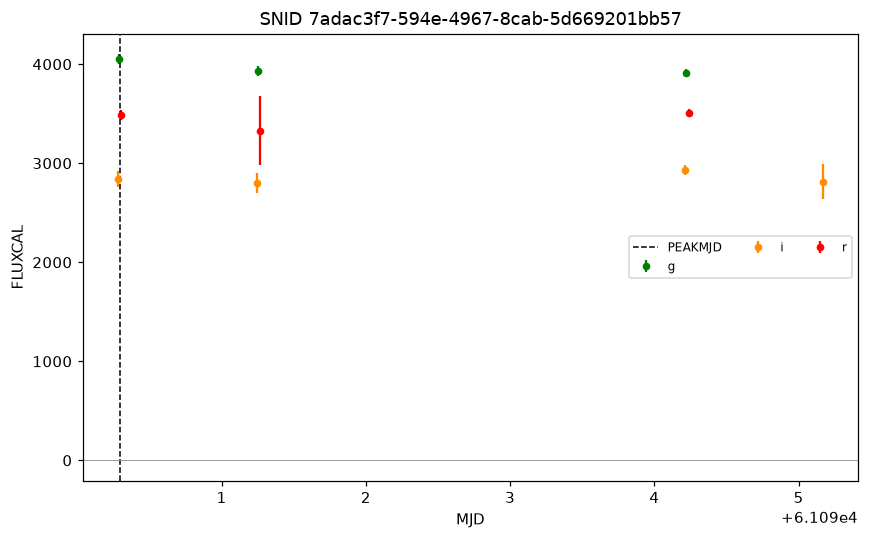

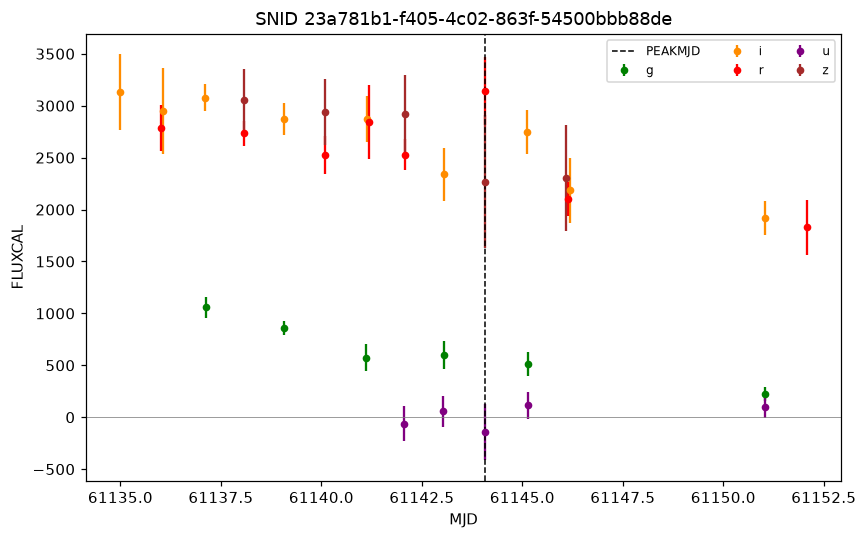

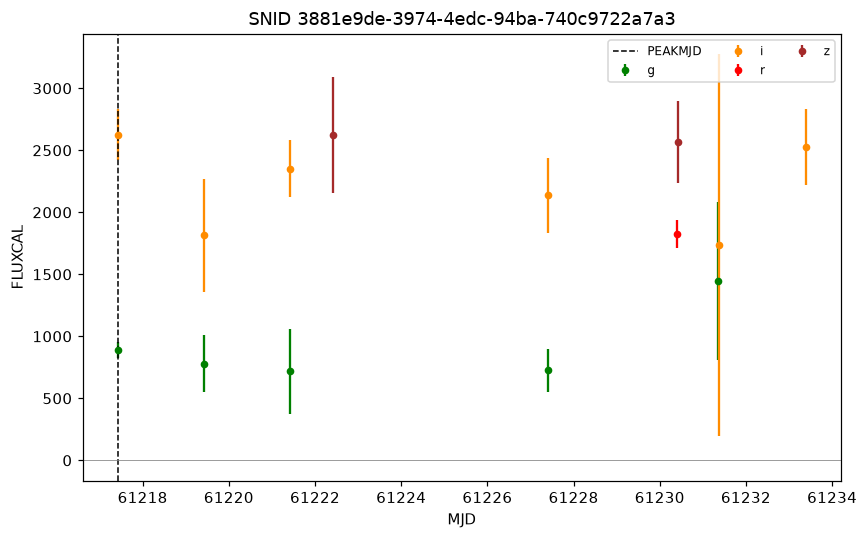

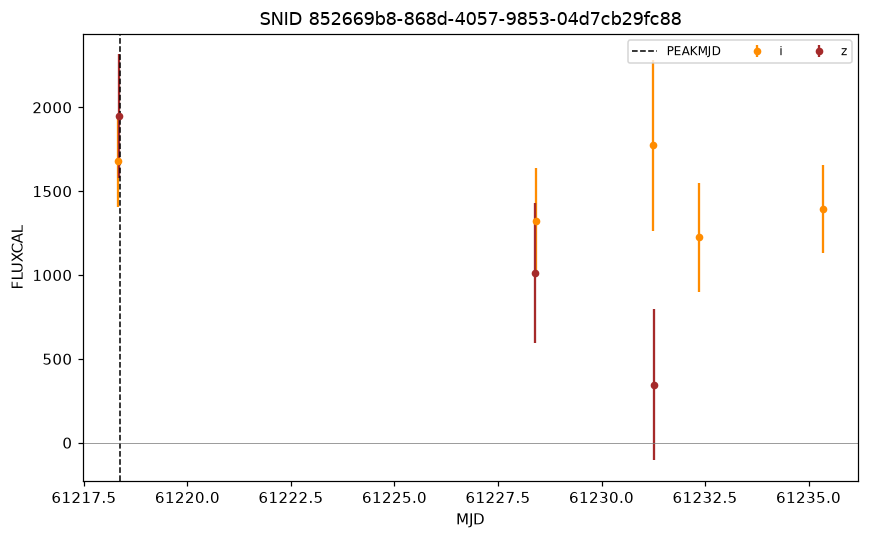

In [43]:
top_cids = rank_df_clean.sort_values(["ia_score", "FITPROB"], ascending=False)["CID"].head(10).tolist()

for cid in top_cids:
    fig, ax = plt.subplots(figsize=(8, 5))
    try:
        plot_lightcurve(cid, ax=ax)
    except ValueError as e:
        ax.set_title(f"{cid}: not found")
        print(e)
    plt.tight_layout()
    plt.show()

### Exploring LCs

In [47]:
import pickle

with open("../results/results_subset/chains.pkl", "rb") as f:
    chains = pickle.load(f)

print(type(chains))
if isinstance(chains, dict):
    for k, v in chains.items():
        shape = getattr(v, "shape", None)
        print(f"  {k}: {type(v)}", f"shape={shape}" if shape else "")

<class 'dict'>
  AV: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  Ds: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  RV: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  RV_tform: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  eps: <class 'numpy.ndarray'> shape=(4, 250, 24, 3313)
  eps_tform: <class 'numpy.ndarray'> shape=(4, 250, 24, 3313)
  theta: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  tmax: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  u: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  z: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  mu: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  delM: <class 'numpy.ndarray'> shape=(4, 250, 3313)
  peak_MJD: <class 'numpy.ndarray'> shape=(4, 250, 3313)


In [50]:
cid_list = fitres["CID"].tolist()
cid_to_idx = {cid: i for i, cid in enumerate(cid_list)}

In [51]:
i_test = cid_to_idx[cid]
print("chains AV mean :", chains["AV"][..., i_test].mean())
print("fit_summary AV[i] mean:", fit_summary.loc[f"AV[{i_test}]", "mean"])

chains AV mean : 7.873530824906158
fit_summary AV[i] mean: 7.874


In [112]:
import jax.numpy as jnp
from bayesn import SEDmodel

cid = "a90065f9-bfa1-4cb3-a8be-79dbfcacdc6a"
i = cid_to_idx[cid]

chains_i = {k: v[..., i:i+1] for k, v in chains.items()}  

model = SEDmodel(
    load_model="T21_model"
)

head_row, phot = find_snid(cid)
obs_bands_short = np.unique(np.char.strip(phot['BAND'].astype(str)))
fit_bands = [[config["map"][b] for b in obs_bands_short]]  # same nested-list shape you used before

model.peak_mjds = np.array([float(head_row['PEAKMJD'])])
model.ebv = np.array([float(head_row['MWEBV'])])

model_mjd, model_mean, model_std = model.get_flux_from_chains_photoz(
    chains=chains_i, bands=fit_bands, num_sne=1, n_grid=200, num_samples=200,
)

Current devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]
Currently working in /Users/jennakempster-taylor/Documents/bayesn-lsst/jkt-project/notebooks
Loading built-in model T21_model
Getting photo-z posterior-predictive light curves from chains...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.80s/it]


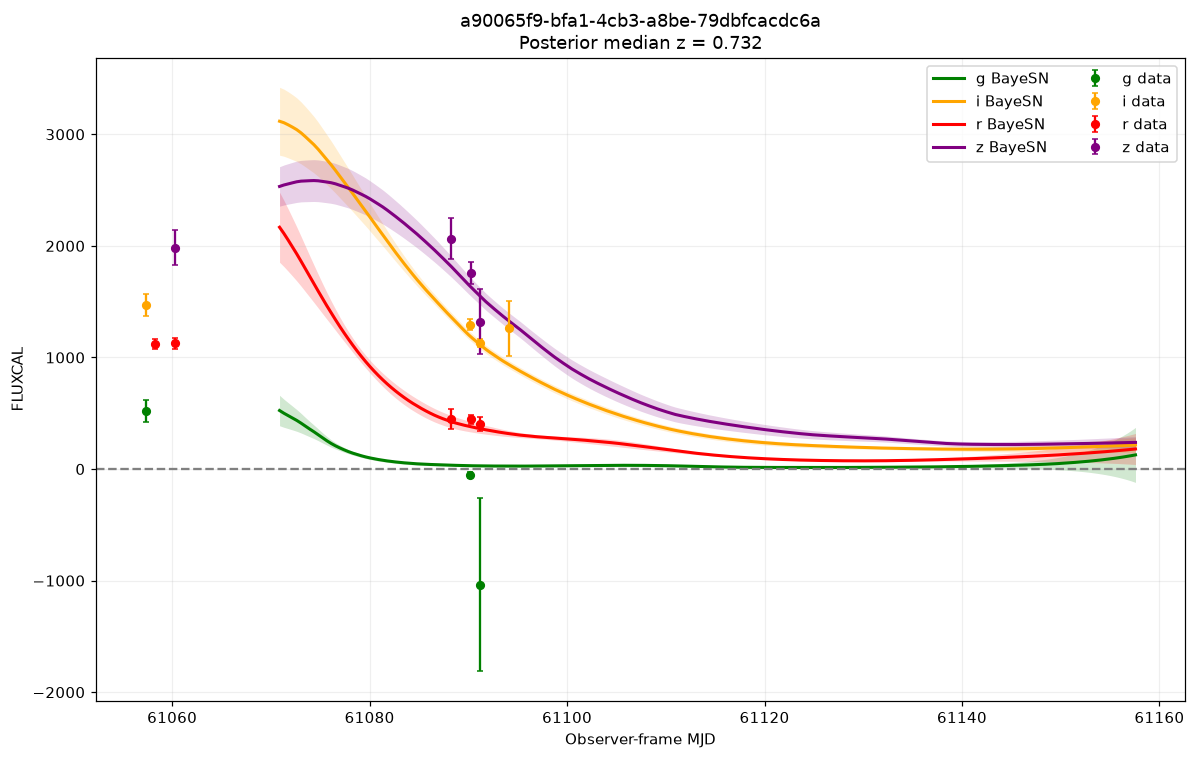

In [113]:
t = np.asarray(phot['MJD'], dtype=float)
flux = np.asarray(phot['FLUXCAL'], dtype=float)
flux_err = np.asarray(phot['FLUXCALERR'], dtype=float)
filters = np.char.strip(phot['BAND'].astype(str))

colours = {"u": "blue", "g": "green", "r": "red", "i": "orange", "z": "purple", "y": "brown"}
observed_bands = obs_bands_short  # already computed above, short band codes present for this SN

z_median = np.median(chains_i['z'])  # posterior z for this specific SN

fig, ax = plt.subplots(figsize=(11, 7))

for band_index, band in enumerate(observed_bands):
    use = filters == band
    colour = colours[band]

    # Observed data
    ax.errorbar(
        t[use],
        flux[use],
        yerr=flux_err[use],
        fmt="o",
        ms=5,
        capsize=2,
        color=colour,
        label=f"{band} data",
        zorder=3,
    )

    # BayeSN prediction
    fitted_flux = model_mean[0, band_index]
    fitted_std = model_std[0, band_index]

    ax.plot(
        model_mjd[0],
        fitted_flux,
        color=colour,
        linewidth=2,
        label=f"{band} BayeSN",
        zorder=2,
    )

    ax.fill_between(
        model_mjd[0],
        fitted_flux - fitted_std,
        fitted_flux + fitted_std,
        color=colour,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )

ax.axhline(0, color="grey", linestyle="--")

ax.set(
    xlabel="Observer-frame MJD",
    ylabel="FLUXCAL",
    title=f"{cid}\nPosterior median z = {z_median:.3f}",
)

ax.legend(ncol=2)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [65]:
import inspect
print(inspect.signature(model.get_flux_from_chains_photoz))
print(inspect.getsource(model.get_flux_from_chains_photoz))

(chains, bands, num_sne, n_grid=100, num_samples=200)
    def get_flux_from_chains_photoz(self, chains, bands, num_sne, n_grid=100, num_samples=200):
        """
        Observer-frame posterior-predictive model light curves for photo-z fits. Each posterior draw uses its
        own redshift for both the K-correction and the rest-frame to observer-MJD time dilation, so the plotted
        band carries the redshift uncertainty. Returns, per SN, a shared observer-MJD grid and the mean and
        standard deviation of the model flux across draws.

        Parameters
        ----------
        chains: dict
            BayeSN photo-z posterior samples, must include a 'z' site.
        bands: array-like
            Per-SN list of bandpasses to evaluate the model in.
        num_sne: int
            Number of SNe to generate light curves for.
        n_grid: int
            Number of observer-MJD grid points per SN.
        num_samples: int
            Number of posterior draws used to form 

In [66]:
print(model_mean.min(), model_mean.max())
print(model_mean.shape)

2.1708195794118272 5269.198307558661
(1, 5, 200)


In [67]:
i = cid_to_idx[cid]
print("theta_rhat:", fitres_merged.loc[fitres_merged['CID']==cid, 'theta_rhat'].values 
      if 'fitres_merged' in dir() else rank_df.loc[rank_df['CID']==cid, 'theta_rhat'].values)
print("FITPROB:", fitres.loc[fitres['CID']==cid, 'FITPROB'].values)

for k in ['theta', 'AV', 'RV', 'tmax', 'mu', 'delM', 'z', 'eps']:
    arr = chains_i[k]
    print(f"{k}: min={np.nanmin(arr):.3g} max={np.nanmax(arr):.3g} "
          f"n_nan={np.isnan(arr).sum()} n_inf={np.isinf(arr).sum()}")

theta_rhat: [1.]
FITPROB: [0.9606]
theta: min=-2.05 max=0.193 n_nan=0 n_inf=0
AV: min=0.00199 max=0.322 n_nan=0 n_inf=0
RV: min=1.26 max=2.55 n_nan=0 n_inf=0
tmax: min=-4.45 max=-2.22 n_nan=0 n_inf=0
mu: min=37.6 max=38.4 n_nan=0 n_inf=0
delM: min=0 max=0 n_nan=0 n_inf=0
z: min=0.414 max=0.507 n_nan=0 n_inf=0
eps: min=-1.76 max=1.26 n_nan=0 n_inf=0


In [80]:
top20 = rank_df_clean.sort_values(["ia_score", "FITPROB"], ascending=False).head(20)
top20[["CID", "ia_score", "FITPROB", "rchi2", "theta_rhat", "theta_hdi_width", "max_gap_days", "NEPOCH"]]

,CID,ia_score,FITPROB,rchi2,theta_rhat,theta_hdi_width,max_gap_days,NEPOCH
740,38733078-e3b2-4817-9a86-64cae48a35fb,6,0.9606,0.665493,1.00,1.336,9.9342,33
327,197705de-ef55-4fad-9cfb-4553e23dfc9f,6,0.9526,0.571942,1.00,2.707,32.0834,11
2923,e10f7cbf-0d69-4b89-a2c1-7f91864a7fdb,6,0.8609,0.712815,1.00,3.202,5.9959,14
2206,a90065f9-bfa1-4cb3-a8be-79dbfcacdc6a,6,0.0842,1.378710,1.00,2.017,27.9090,16
2361,b3428a9a-e072-48f0-b2ed-9e6f7a2be1c1,6,0.0607,1.394229,1.00,1.309,19.0143,22
707,3389b047-0124-4d13-b722-8ac774c13604,6,0.0464,1.508442,1.00,3.373,7.0568,13
1582,7adac3f7-594e-4967-8cab-5d669201bb57,5,0.9992,0.318757,1.00,2.638,2.9482,10
442,23a781b1-f405-4c02-863f-54500bbb88de,5,0.9975,0.513467,1.01,2.367,4.8542,33
747,3881e9de-3974-4edc-94ba-740c9722a7a3,5,0.9956,0.430204,1.01,3.352,4.9989,14
1719,852669b8-868d-4057-9853-04d7cb29fc88,5,0.9885,0.432786,1.00,3.729,10.0344,8


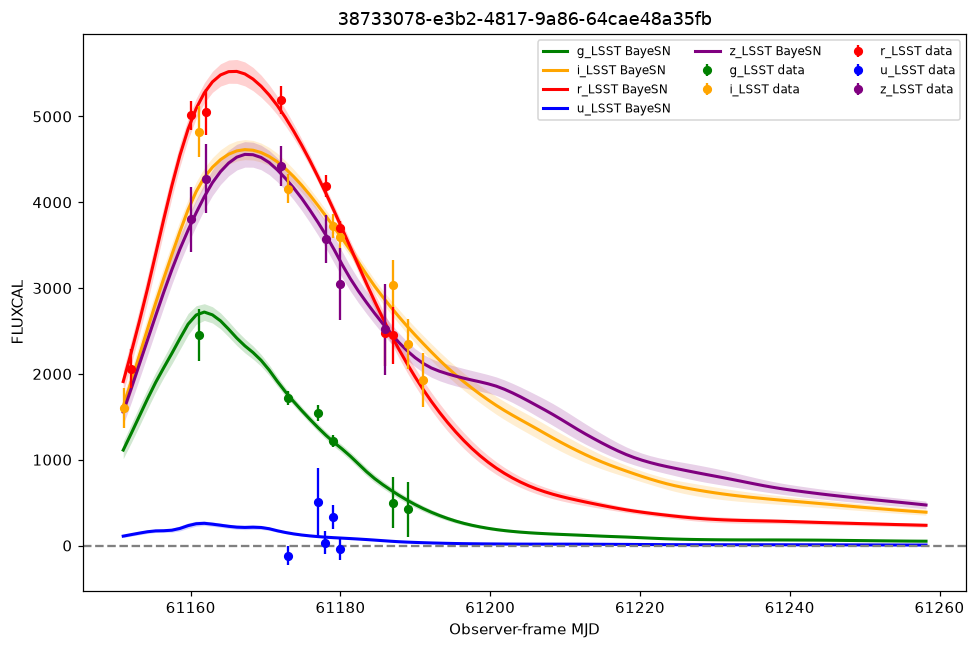

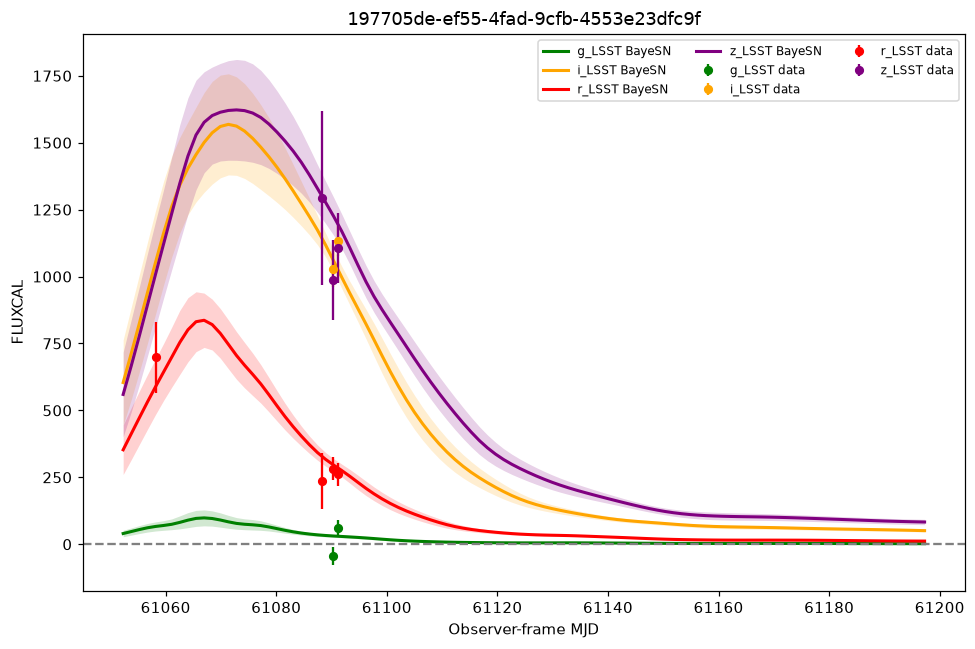

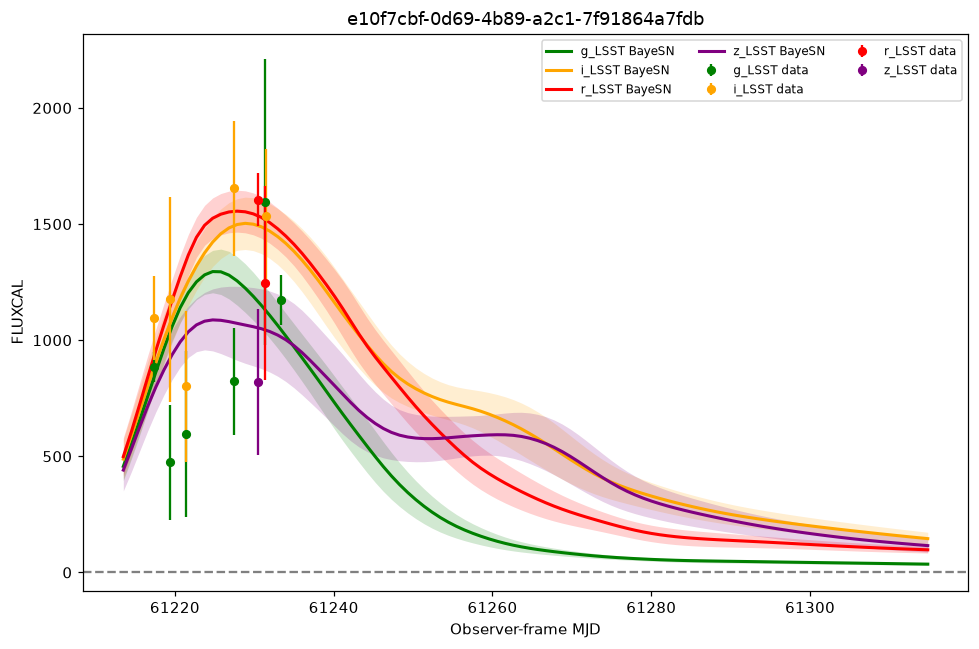

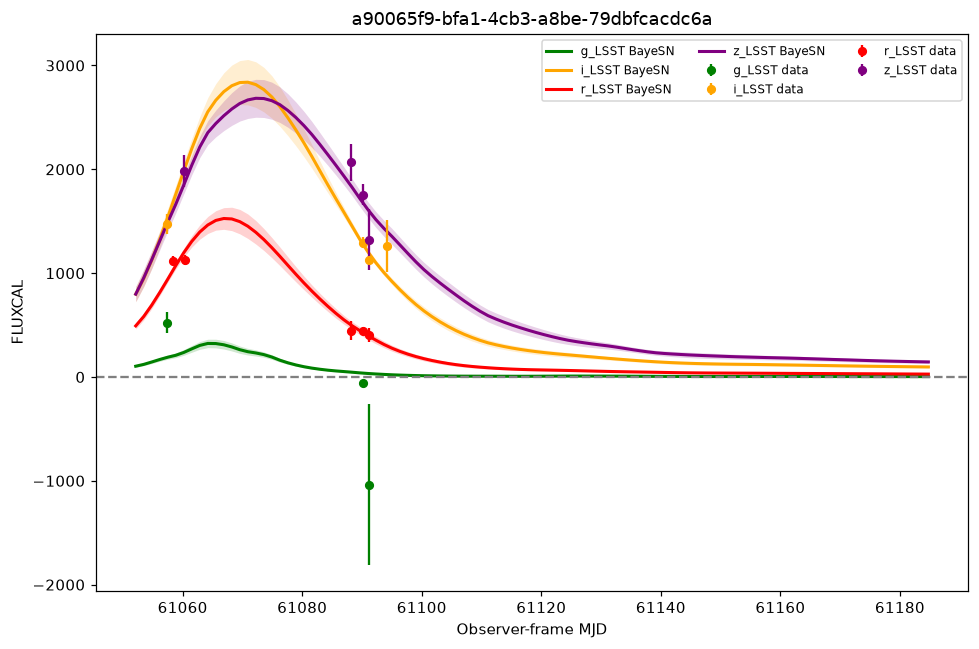

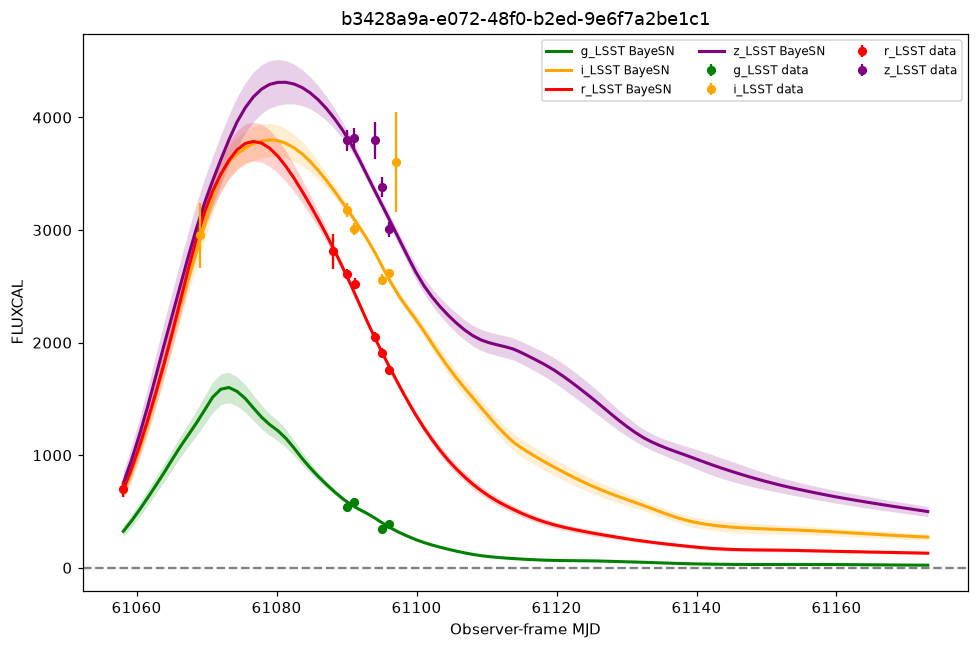

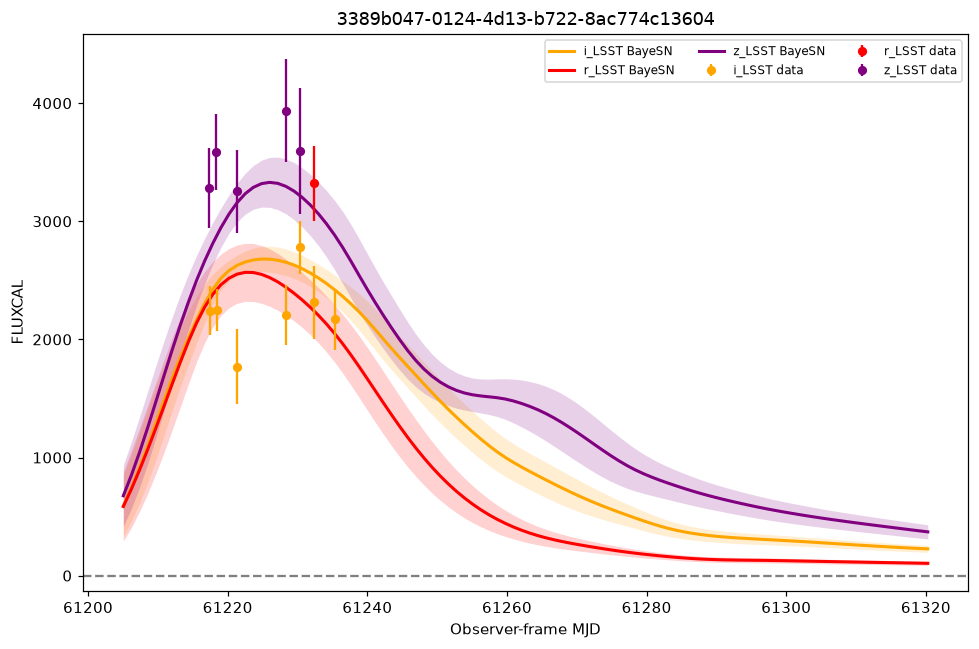

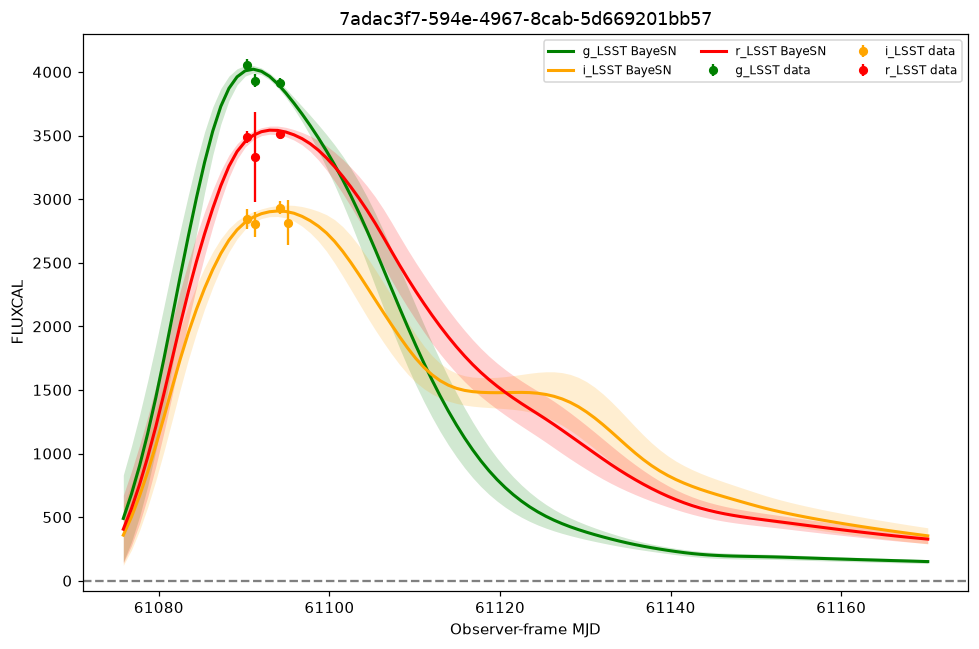

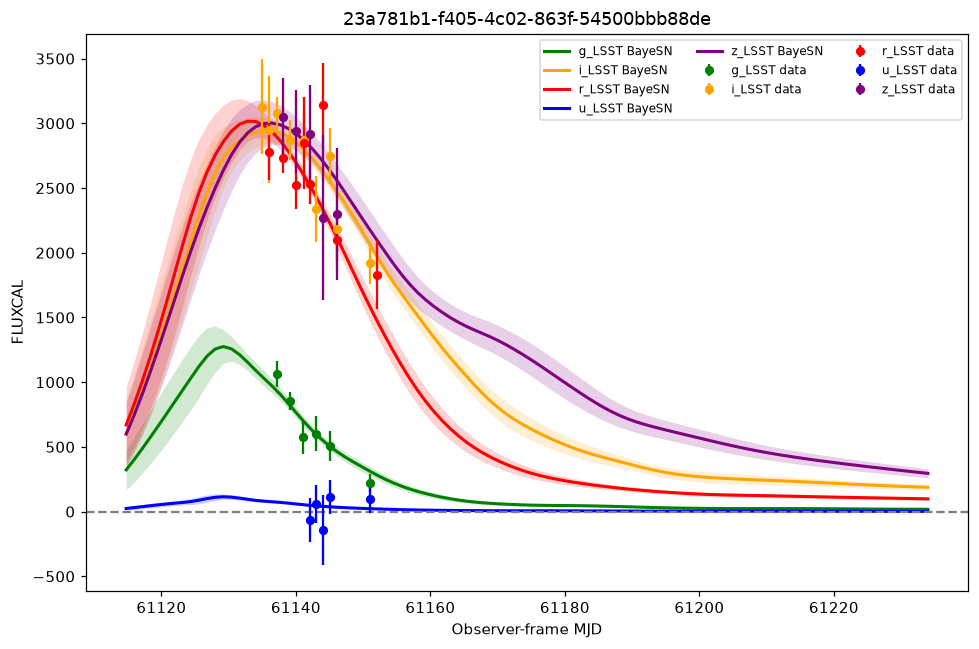

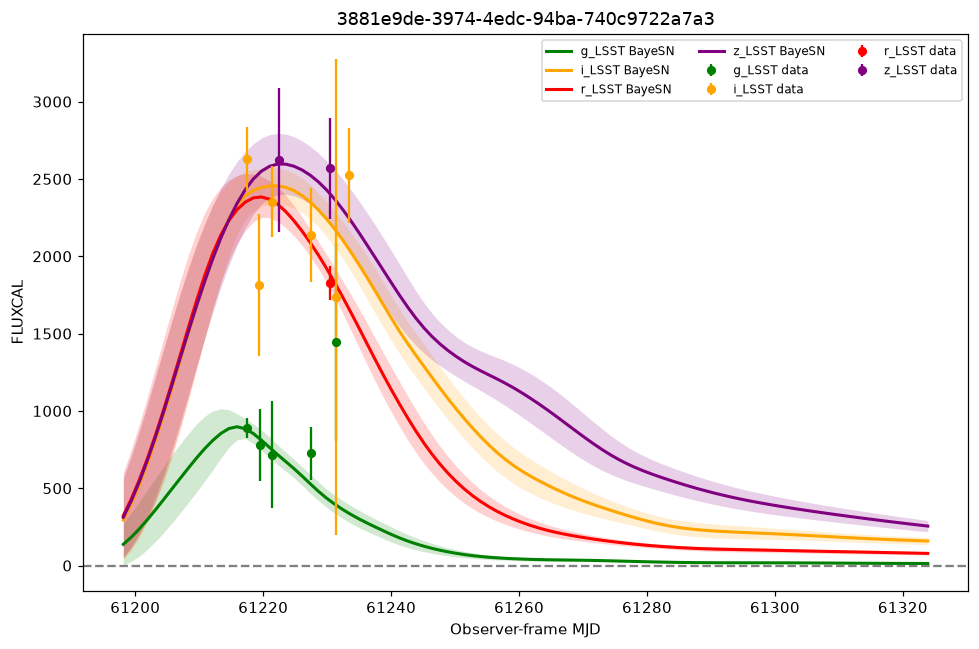

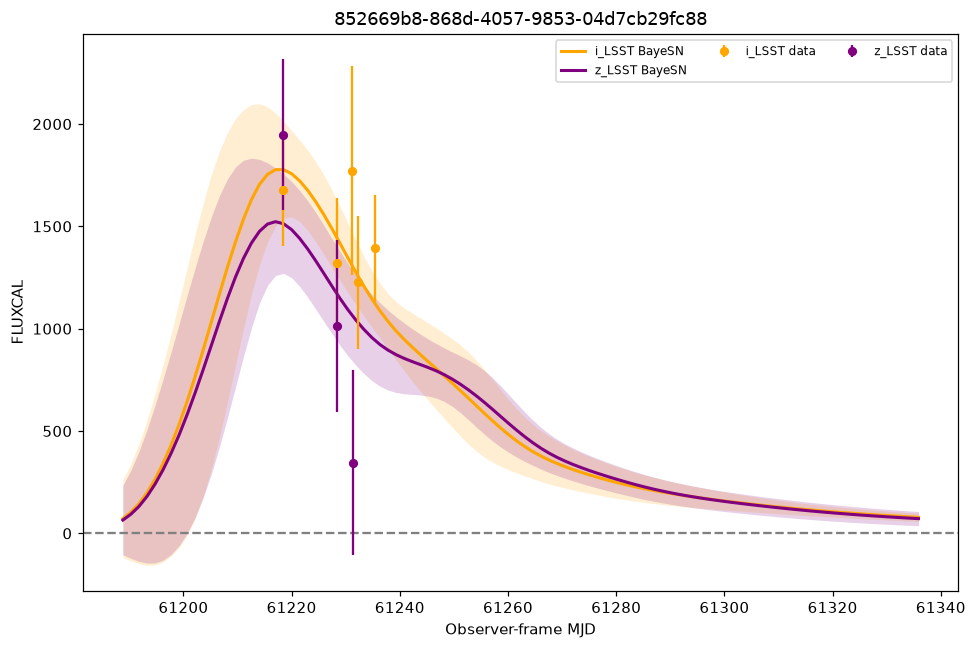

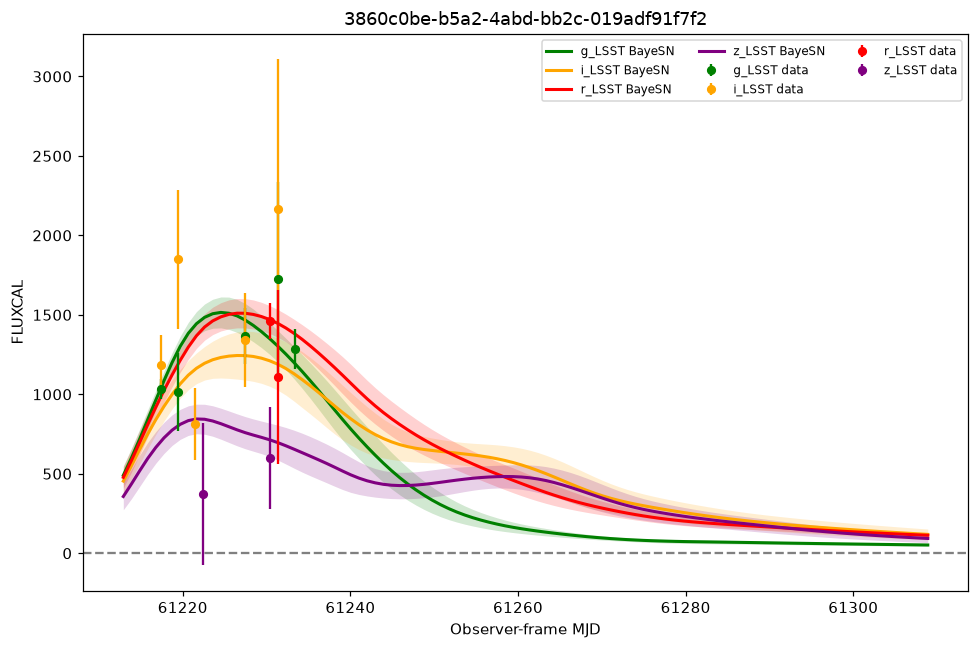

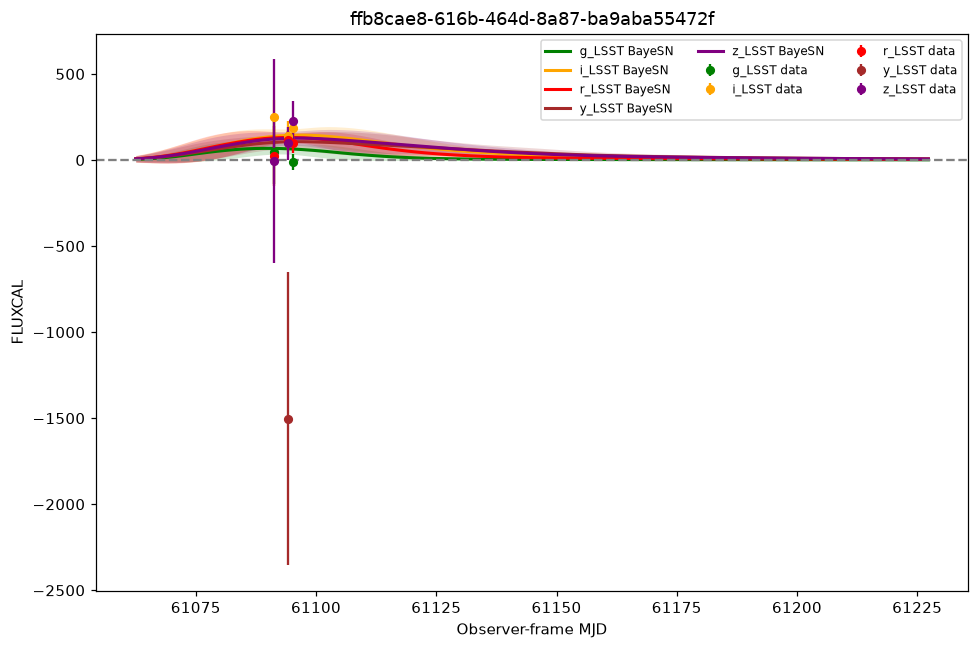

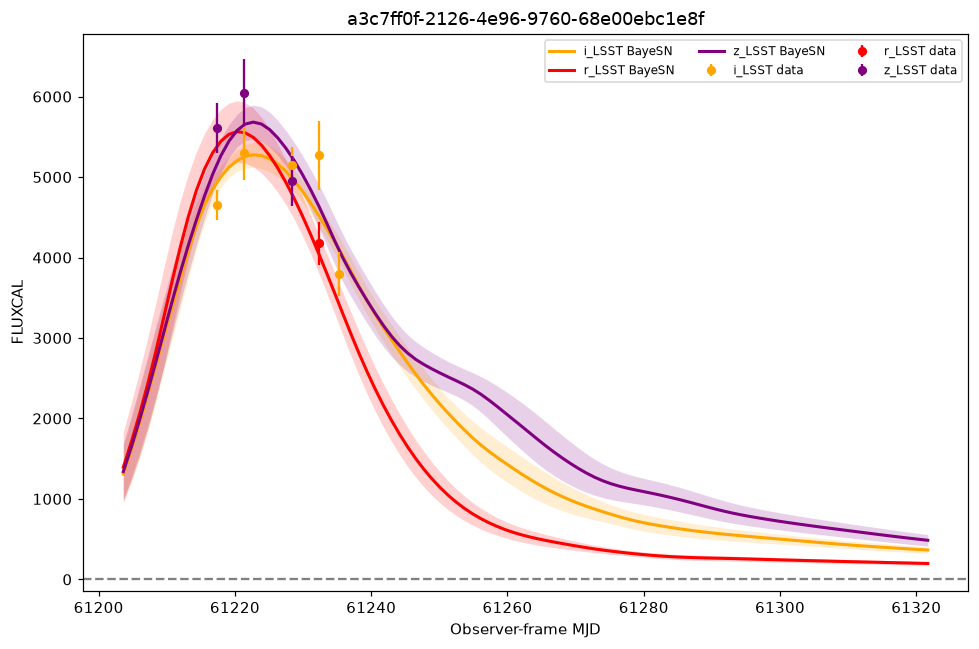

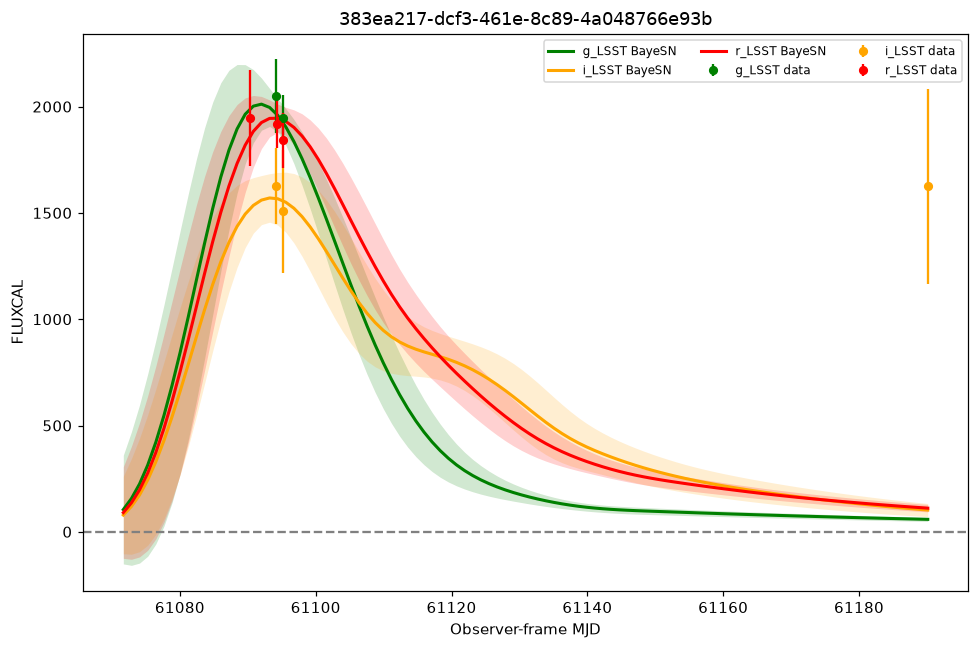

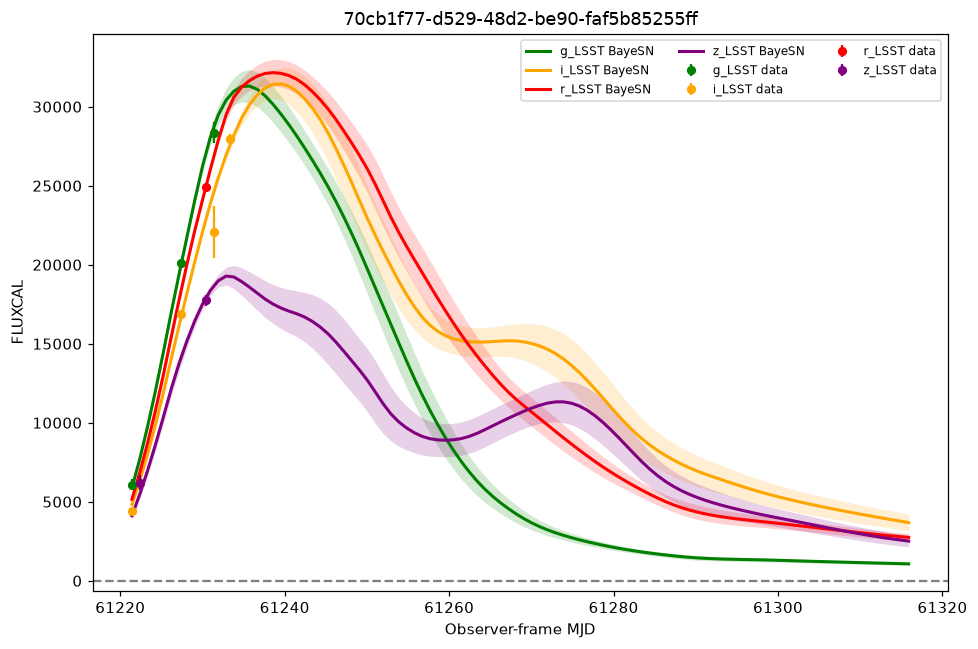

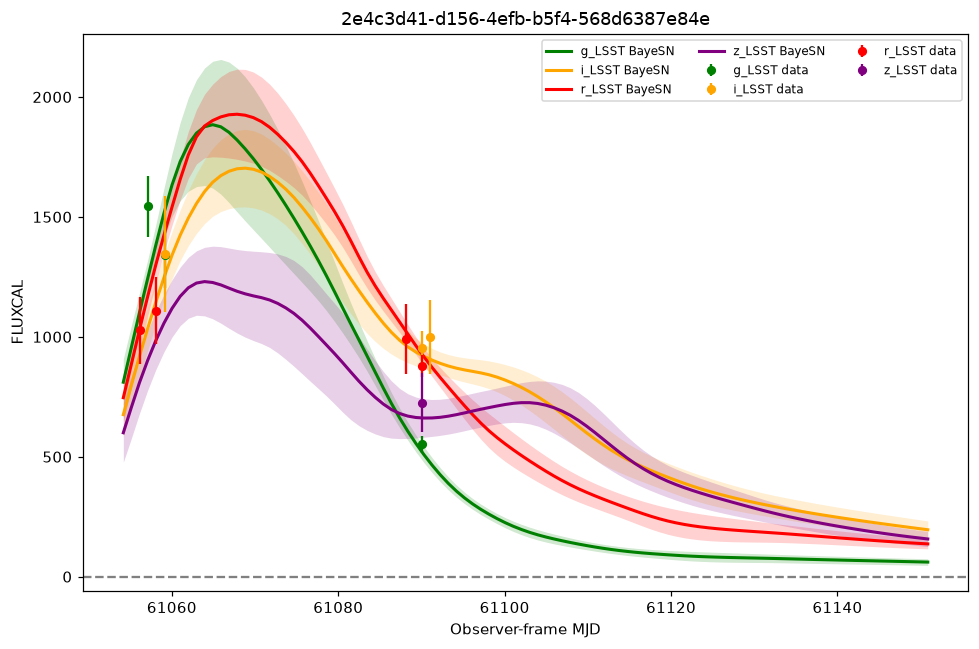

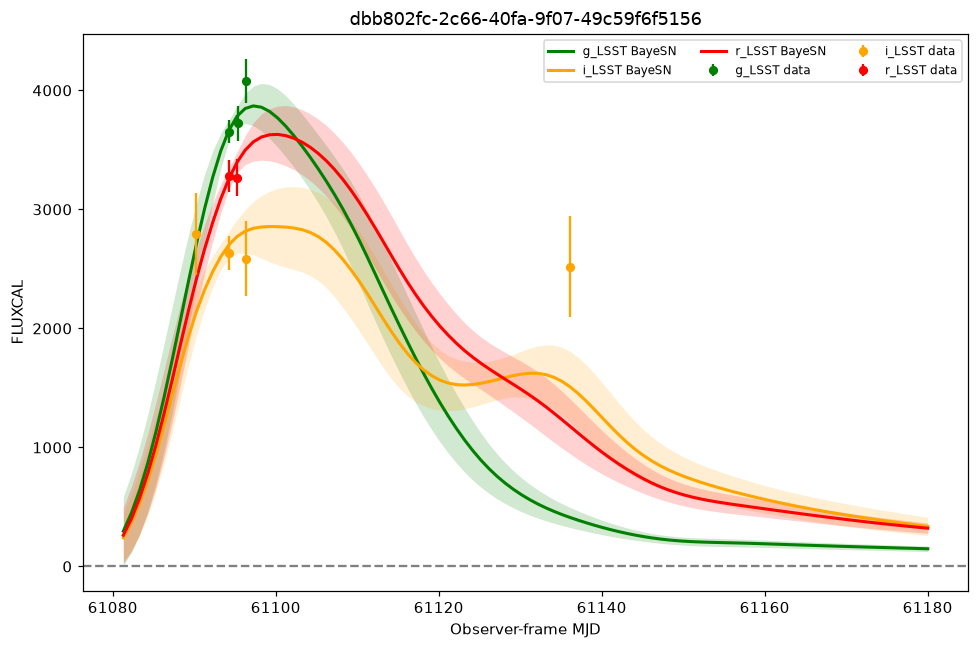

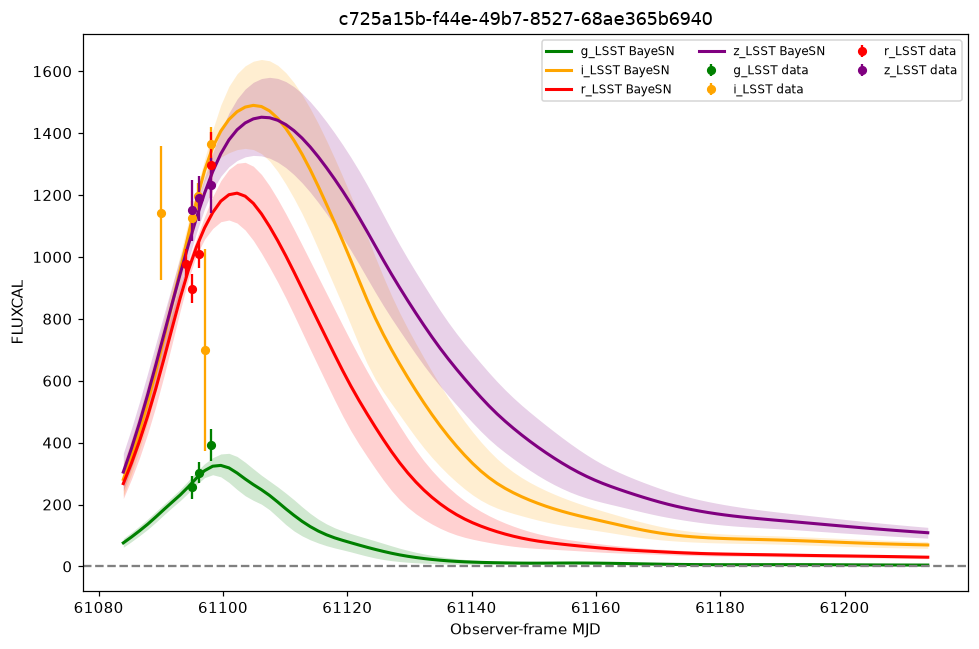

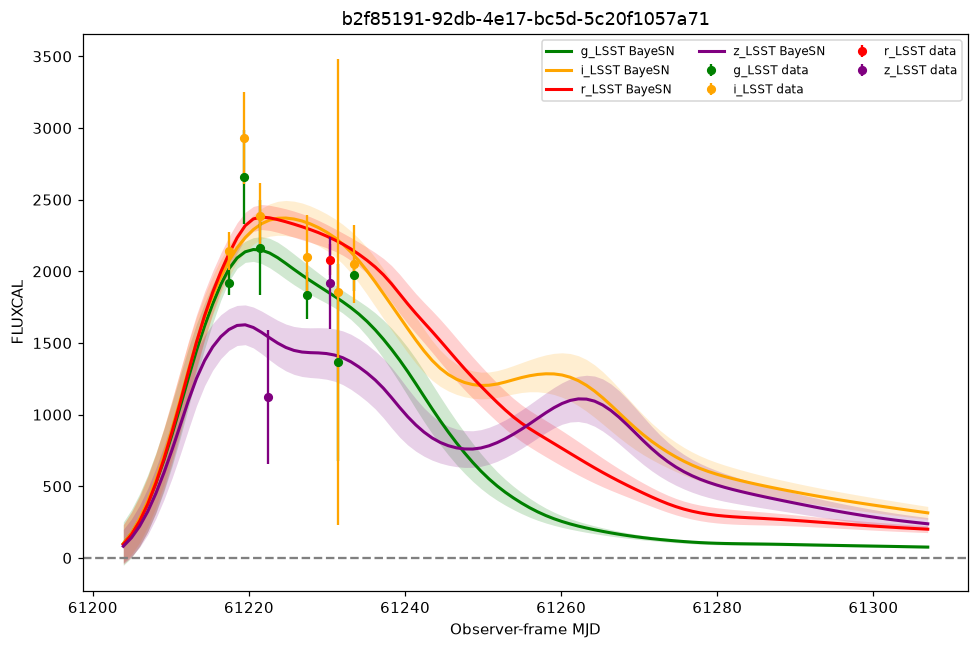

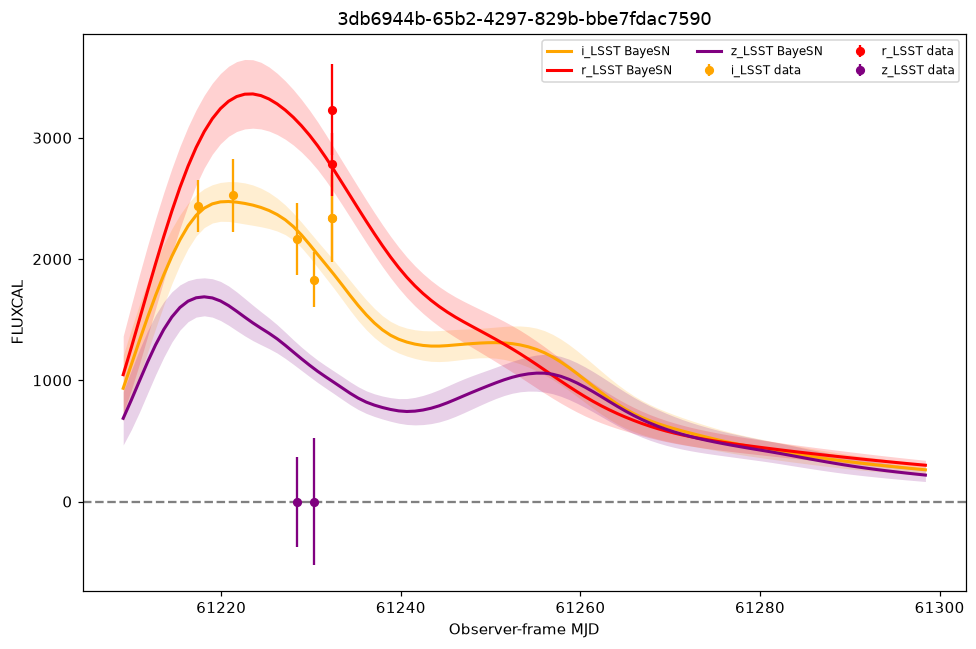

In [116]:
lcplot = pd.read_csv("../results/results_subset/output.LCPLOT")  # ~136MB, ~1.33M rows, loads fine in memory

BAND_COLORS_FULL = {
    "u_LSST": "blue", "g_LSST": "green", "r_LSST": "red",
    "i_LSST": "orange", "z_LSST": "purple", "y_LSST": "brown",
}

def plot_lightcurve_lcplot(cid, ax=None):
    sub = lcplot[lcplot["CID"] == cid]
    data = sub[sub["DATA_FLAG"] == 1]
    model = sub[sub["DATA_FLAG"] == 0].sort_values("MJD")

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 6))

    for band in sorted(sub["FLT"].unique()):
        colour = BAND_COLORS_FULL.get(band, "black")

        d = data[data["FLT"] == band]
        ax.errorbar(d["MJD"], d["FLUXCAL"], yerr=d["FLUXCALERR"],
                    fmt="o", ms=5, color=colour, label=f"{band} data", zorder=3)

        m = model[model["FLT"] == band]
        ax.plot(m["MJD"], m["FLUXCAL"], color=colour, lw=2, label=f"{band} BayeSN", zorder=2)
        ax.fill_between(m["MJD"], m["FLUXCAL"] - m["FLUXCALERR"], m["FLUXCAL"] + m["FLUXCALERR"],
                         color=colour, alpha=0.18, linewidth=0, zorder=1)

    ax.axhline(0, color="grey", ls="--")
    ax.set(xlabel="Observer-frame MJD", ylabel="FLUXCAL", title=cid)
    ax.legend(fontsize=8, ncol=3)
    return ax


top20_cids = top20["CID"].tolist()

for cid in top20_cids:
    fig, ax = plt.subplots(figsize=(9, 6))
    plot_lightcurve_lcplot(cid, ax=ax)
    plt.tight_layout()
    plt.show()

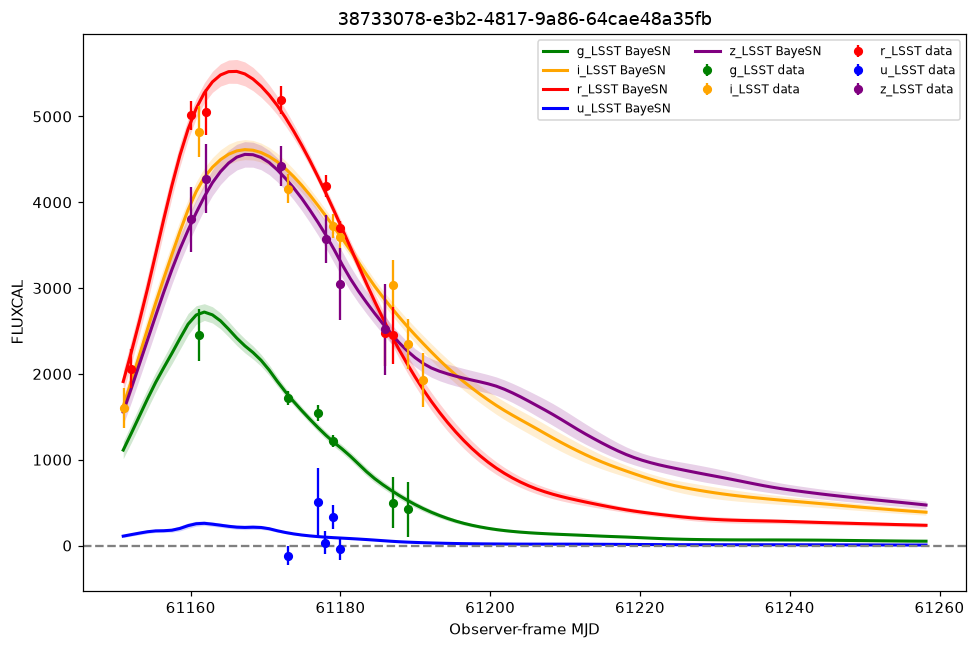

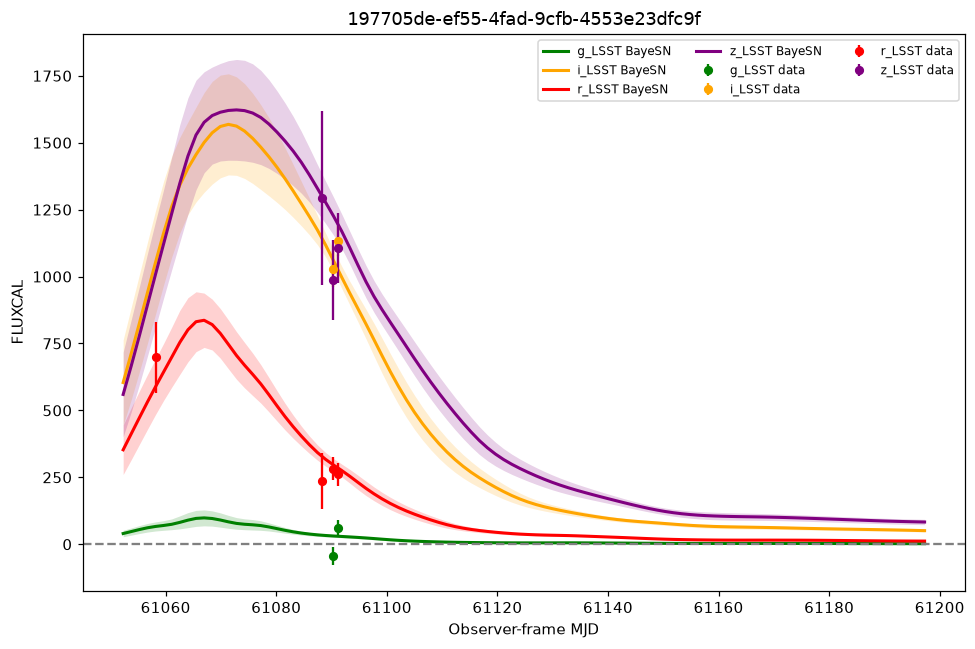

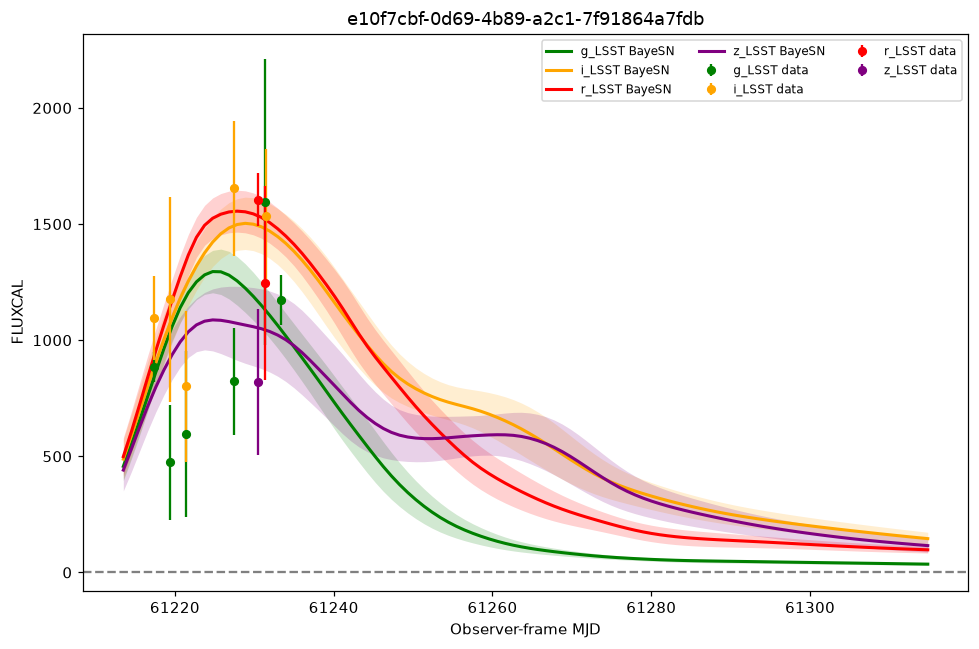

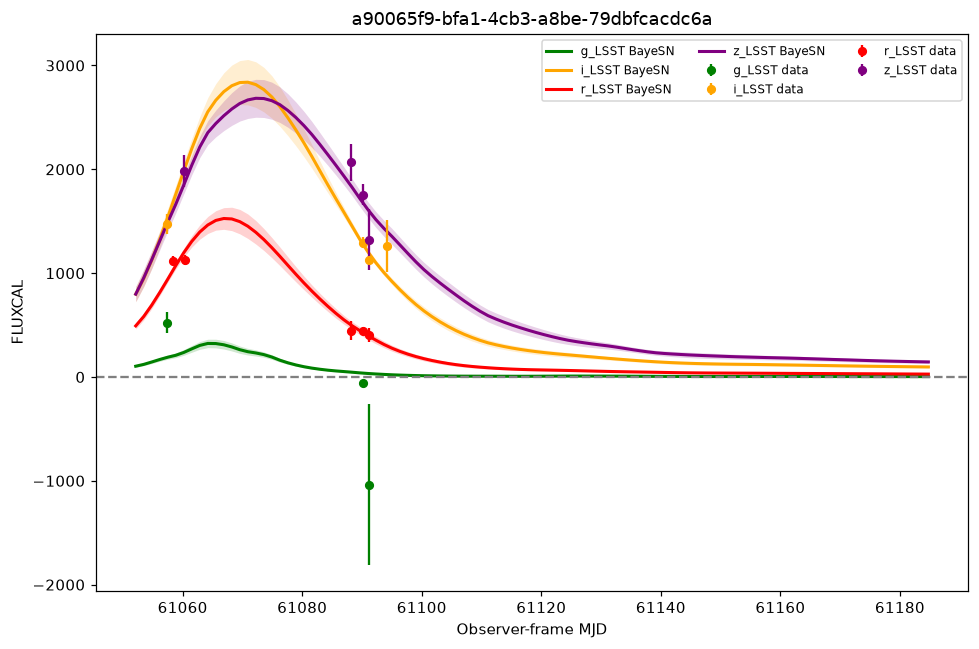

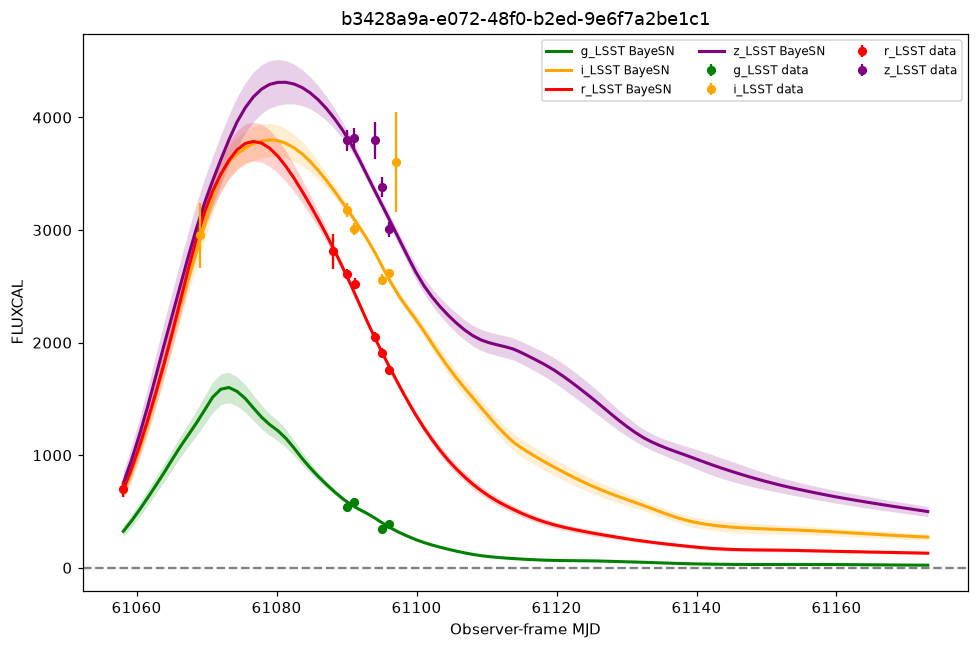

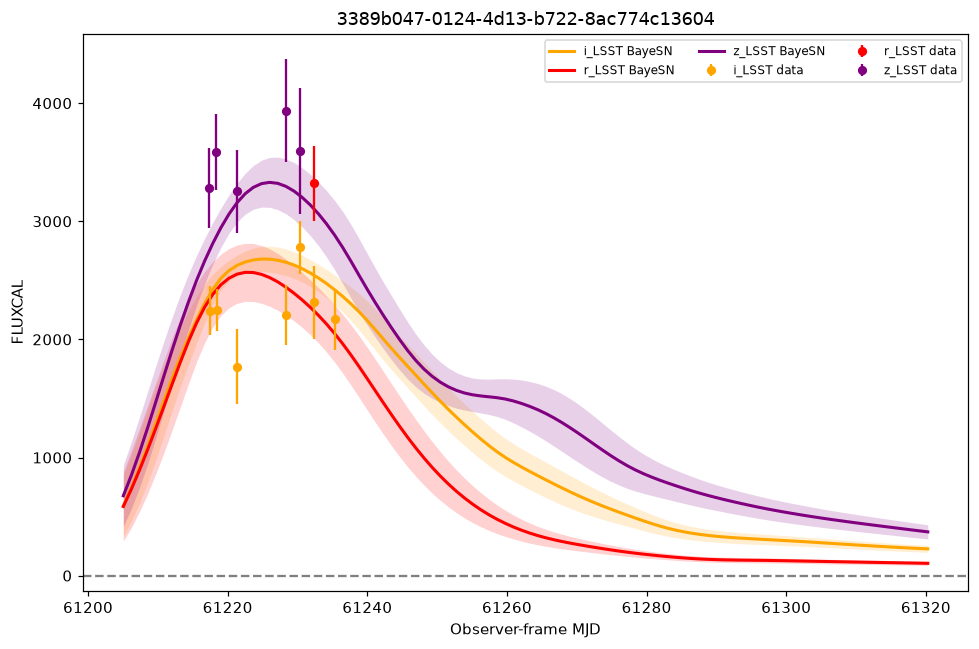

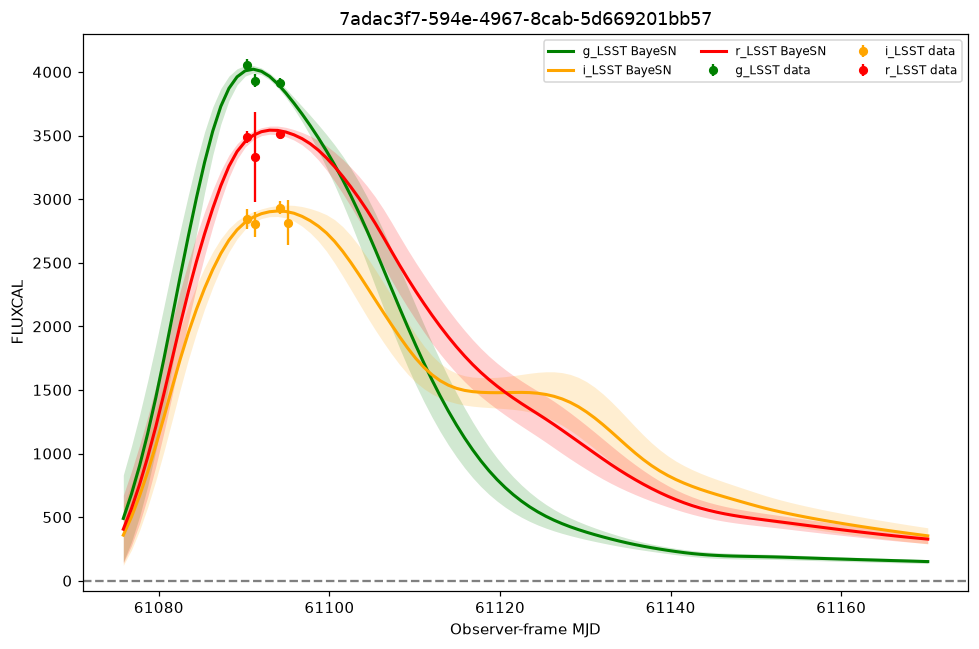

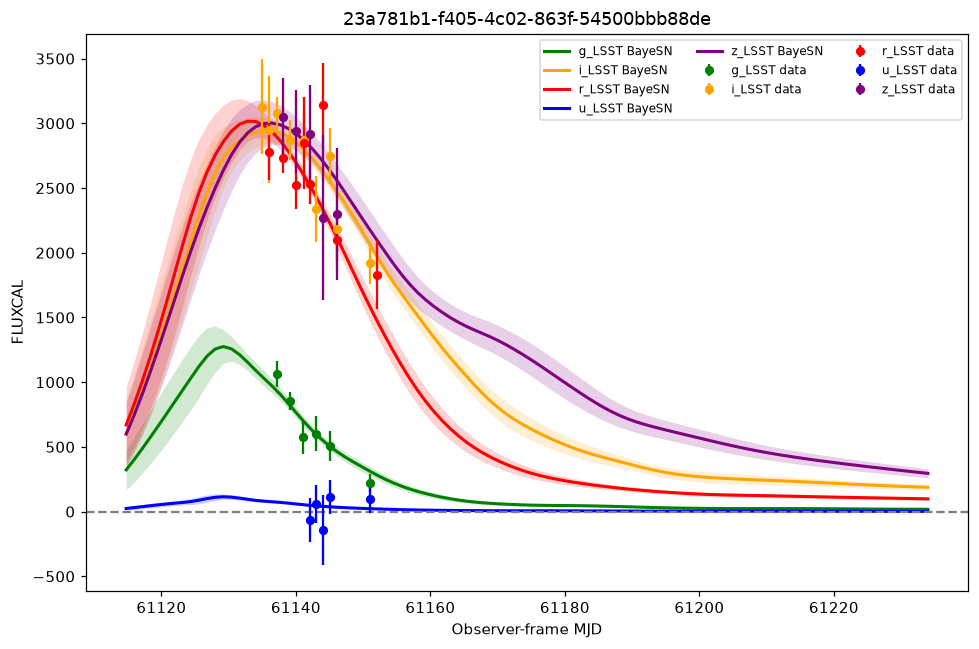

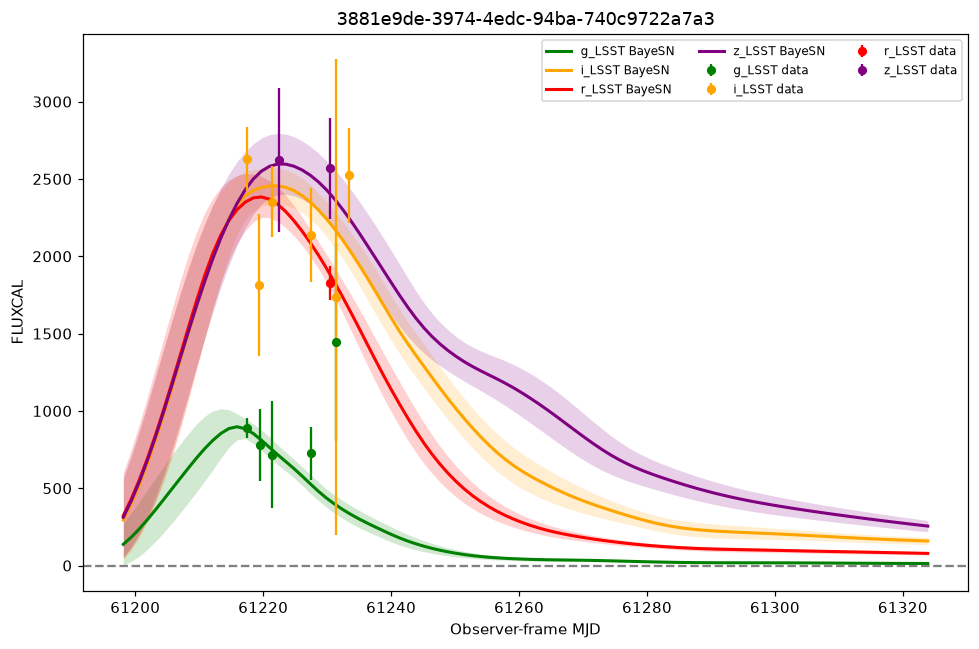

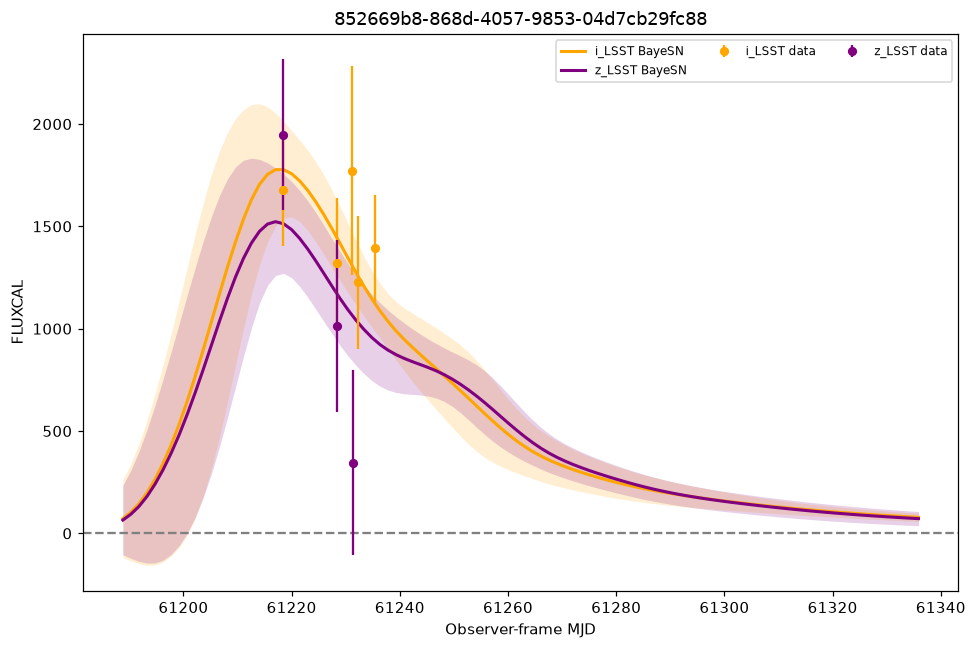

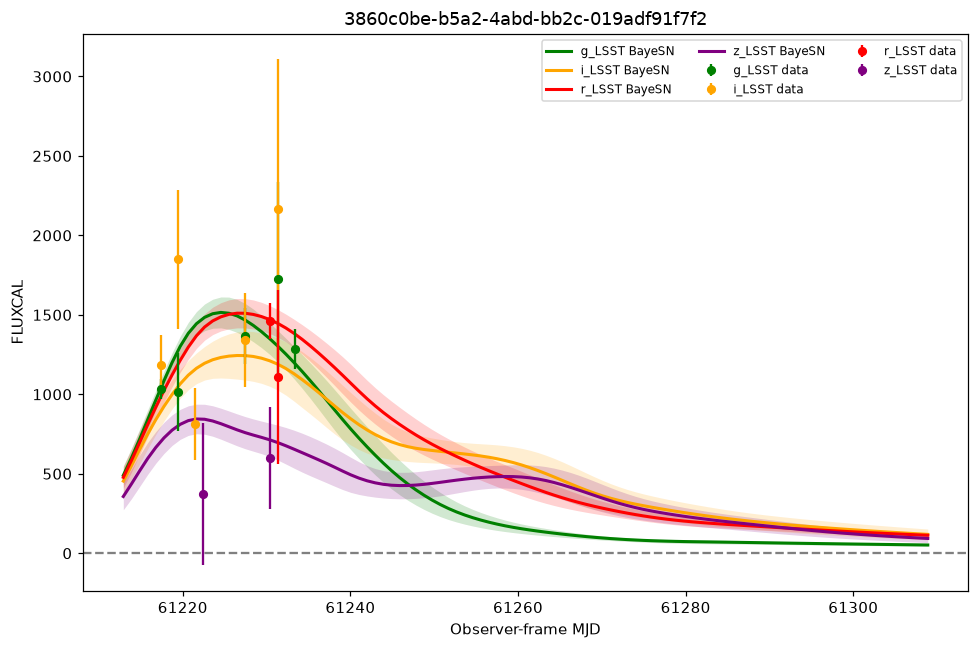

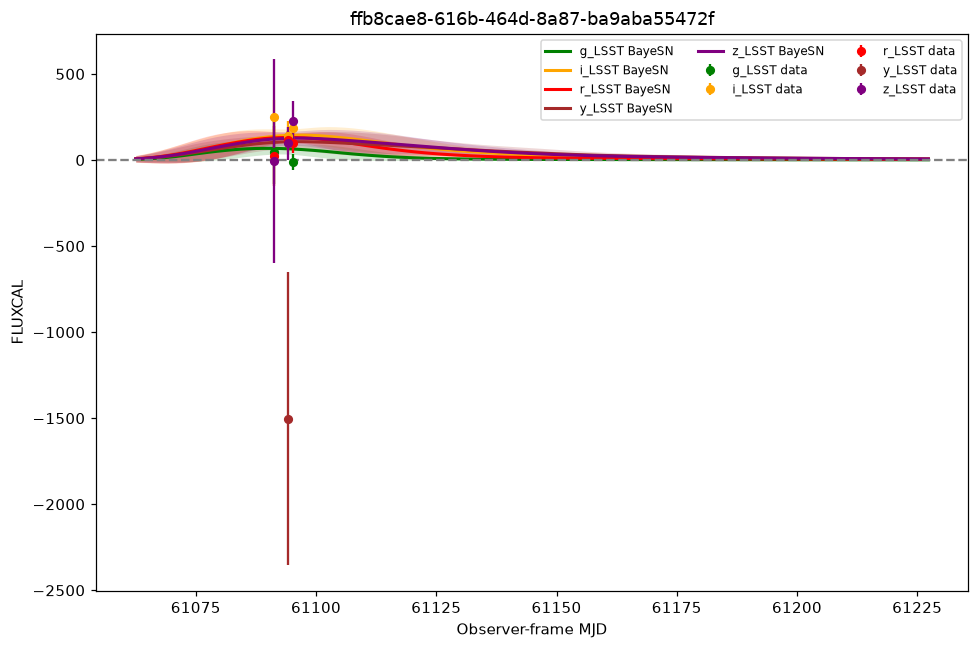

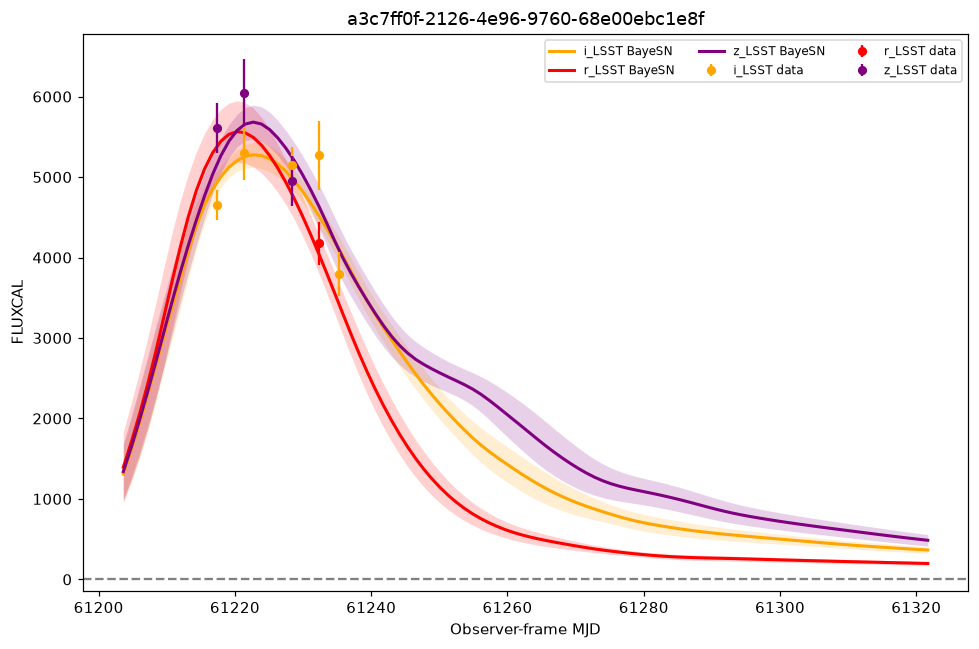

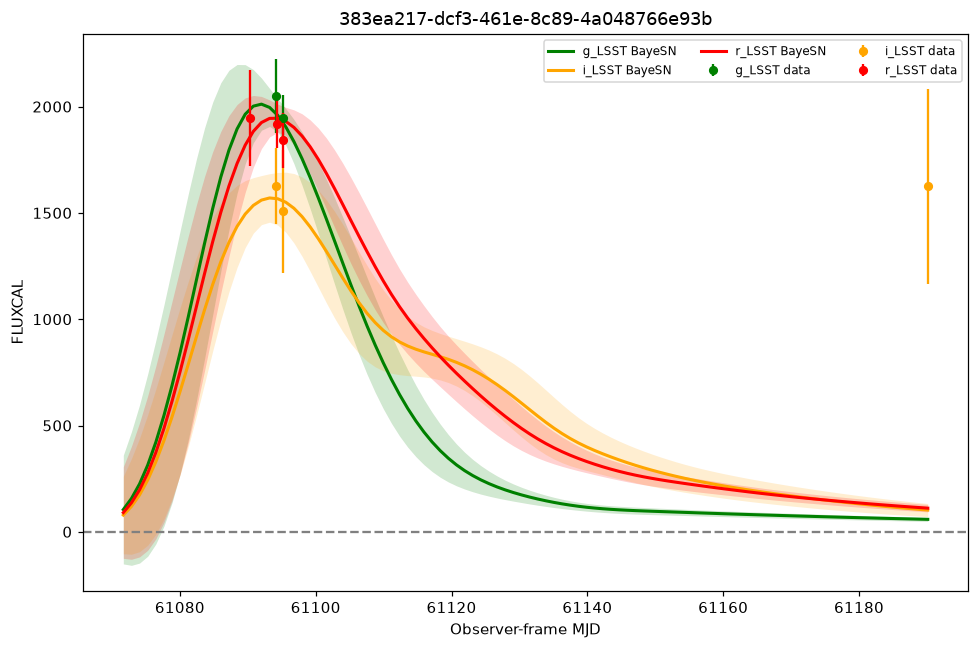

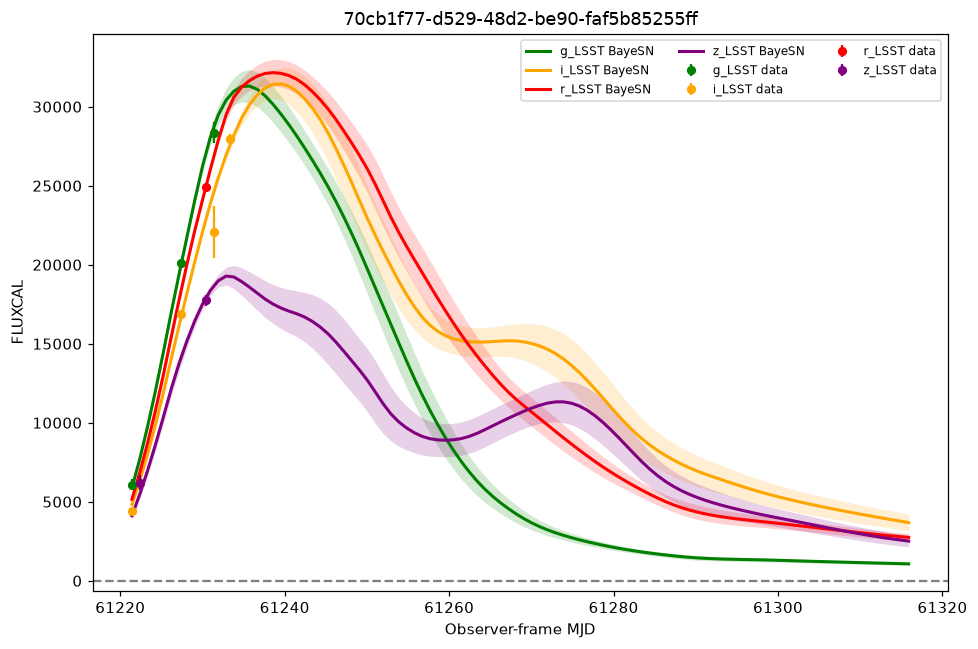

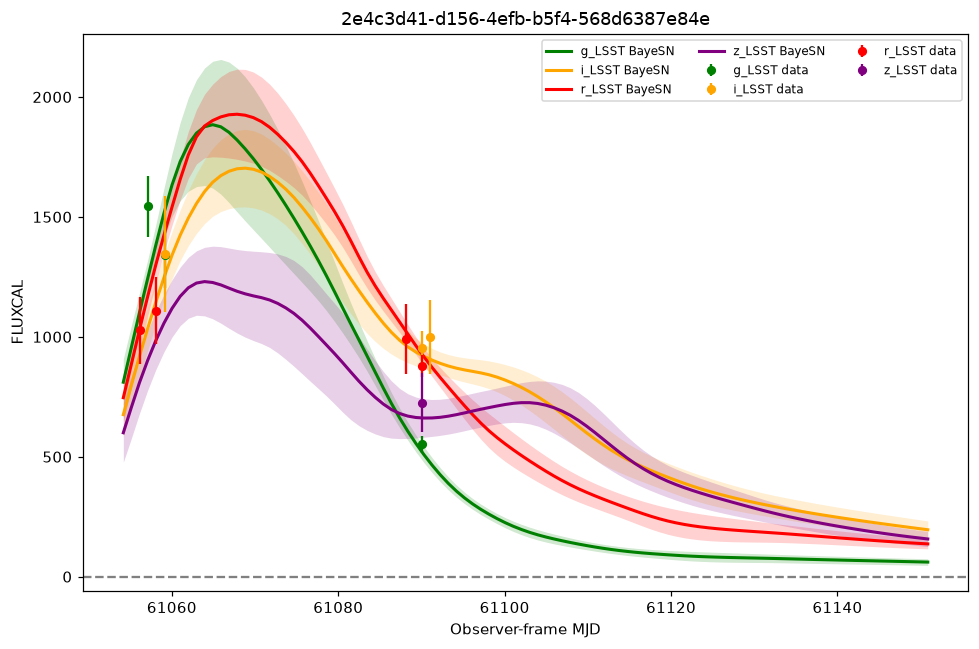

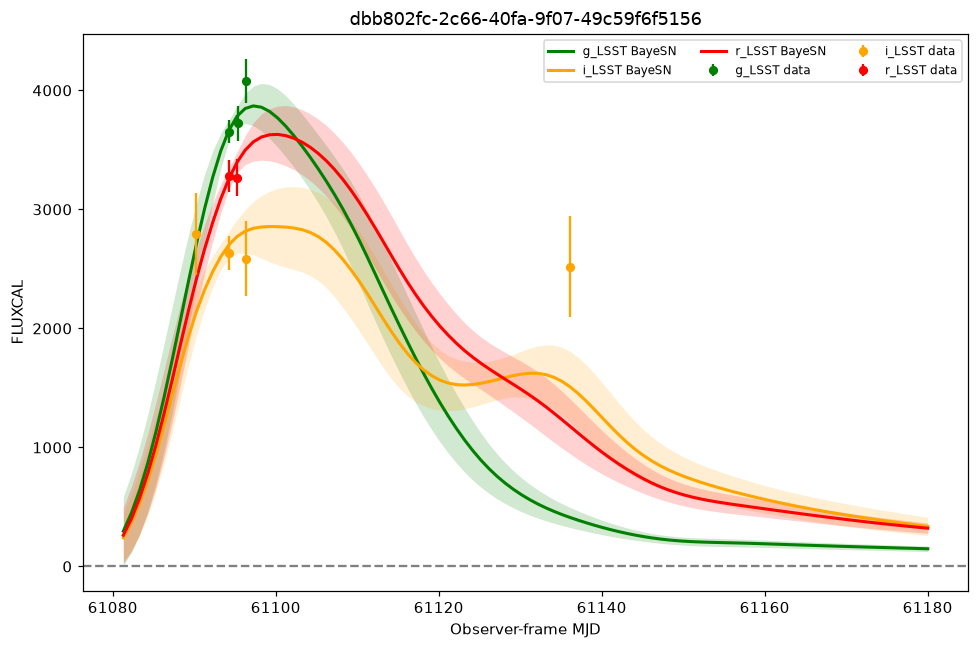

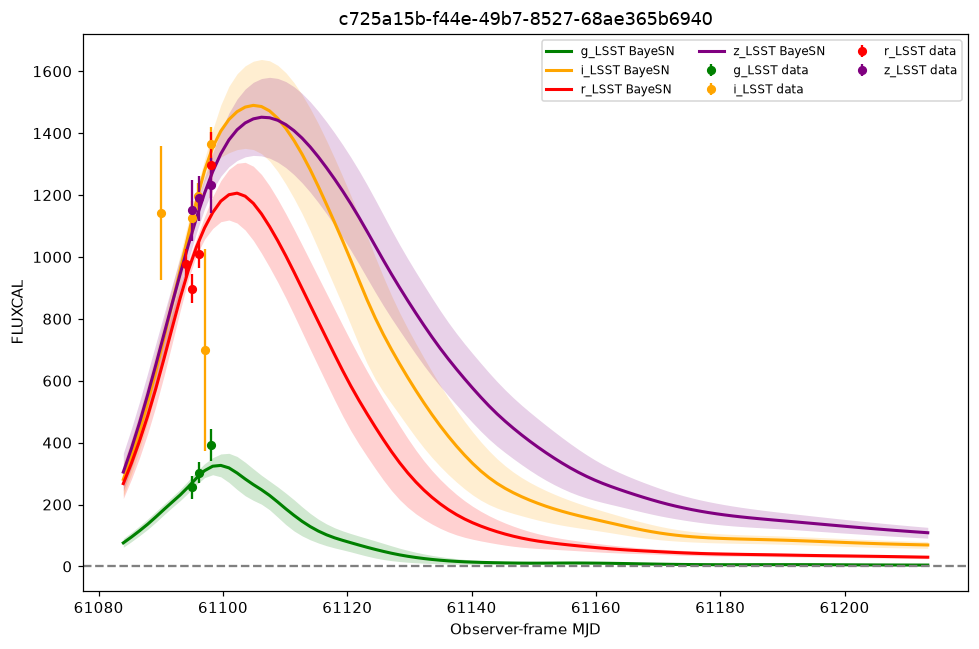

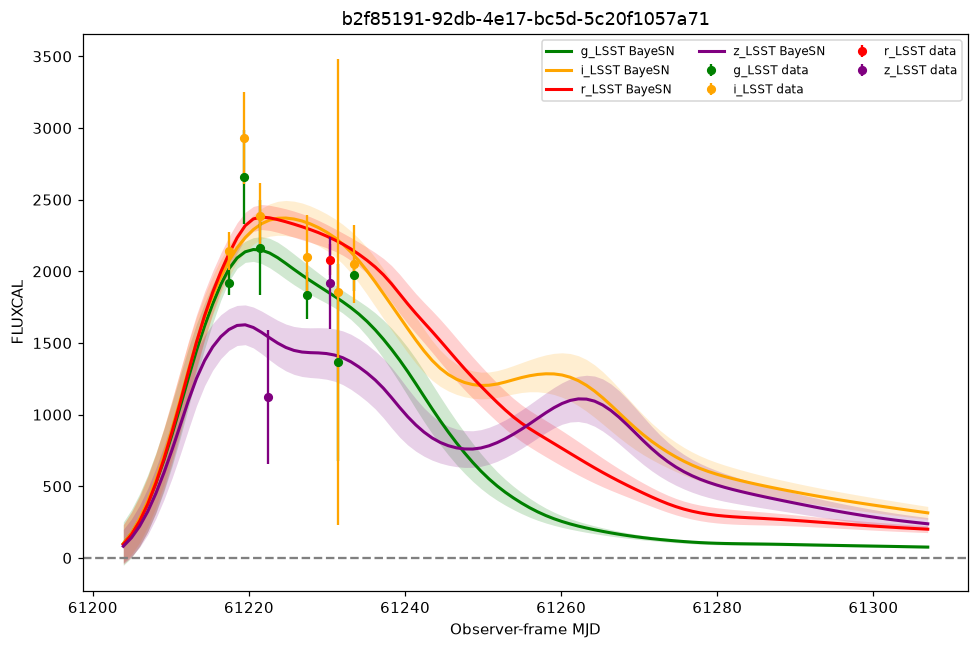

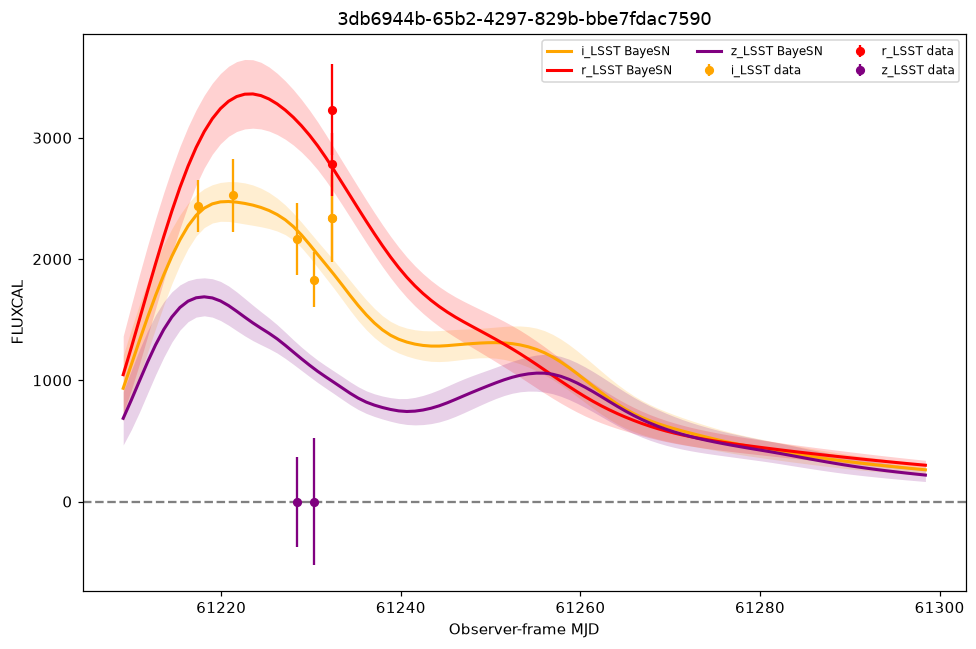

In [117]:
import os

outdir = os.path.expanduser("~/Documents/bayesn-lsst/jkt-project/results/top20_lightcurves")
os.makedirs(outdir, exist_ok=True)

for rank, cid in enumerate(top20_cids, start=1):
    fig, ax = plt.subplots(figsize=(9, 6))
    plot_lightcurve_lcplot(cid, ax=ax)
    plt.tight_layout()
    fig.savefig(os.path.join(outdir, f"{rank:02d}_{cid}.png"), dpi=150, bbox_inches="tight")
    plt.show()

In [107]:
top20 = rank_df_clean.sort_values(["ia_score", "FITPROB"], ascending=False).head(20)
top20_cids = top20["CID"].tolist()

print(len(top20_cids))
print(top20_cids[:5])

20
['38733078-e3b2-4817-9a86-64cae48a35fb', '197705de-ef55-4fad-9cfb-4553e23dfc9f', 'e10f7cbf-0d69-4b89-a2c1-7f91864a7fdb', 'a90065f9-bfa1-4cb3-a8be-79dbfcacdc6a', 'b3428a9a-e072-48f0-b2ed-9e6f7a2be1c1']


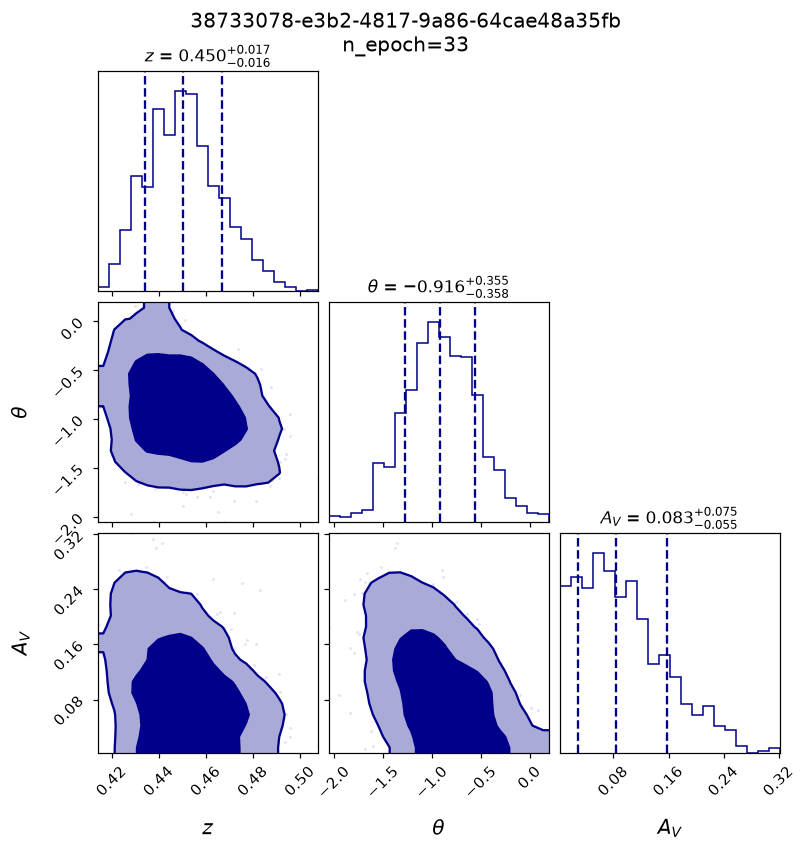

Correlation matrix (z, theta, AV):
[[ 1.    -0.294 -0.323]
 [-0.294  1.    -0.497]
 [-0.323 -0.497  1.   ]]


In [120]:
import corner
import numpy as np
import matplotlib.pyplot as plt

def corner_for_sn(cid, chains, cid_to_idx, params=("z", "theta", "AV"),
                   labels=None, fig=None, color="k", **corner_kwargs):
    """
    Build a corner plot for one SN from the BayeSN chains dict.

    chains : dict of arrays, each shape (n_chains, n_samples, n_sn)
    cid    : SN identifier, must be a key in cid_to_idx
    params : which chains keys to plot together
    """
    i = cid_to_idx[cid]

    # flatten (n_chains, n_samples) -> (n_chains*n_samples,) for each param,
    # stack into (n_draws, n_params)
    samples = np.column_stack([
        chains[p][..., i].reshape(-1) for p in params
    ])

    if labels is None:
        label_map = {"z": r"$z$", "theta": r"$\theta$", "AV": r"$A_V$",
                     "RV": r"$R_V$", "tmax": r"$t_{\max}$",
                     "mu": r"$\mu$", "delM": r"$\delta M$"}
        labels = [label_map.get(p, p) for p in params]

    fig = corner.corner(
        samples,
        labels=labels,
        fig=fig,
        color=color,
        quantiles=[0.16, 0.5, 0.84],
        show_titles=True,
        title_fmt=".3f",
        title_kwargs={"fontsize": 11},
        label_kwargs={"fontsize": 13},
        plot_datapoints=True,
        fill_contours=True,
        levels=(0.68, 0.95),
        smooth=1.0,
        **corner_kwargs,
    )
    return fig, samples

# -- best-sampled SN (top20, rank 1) ---
cid_best = top20_cids[0]   # '38733078-e3b2-4817-9a86-64cae48a35fb'

fig, samples = corner_for_sn(
    cid_best, chains, cid_to_idx,
    params=("z", "theta", "AV"),
    color="darkblue",
)
fig.suptitle(f"{cid_best}\nn_epoch={fitres.loc[fitres.CID==cid_best,'NEPOCH'].values[0]}",
             fontsize=13, y=1.02)
plt.show()

# quick numeric summary of the tradeoffs
corr = np.corrcoef(samples.T)
print("Correlation matrix (z, theta, AV):")
print(np.round(corr, 3))

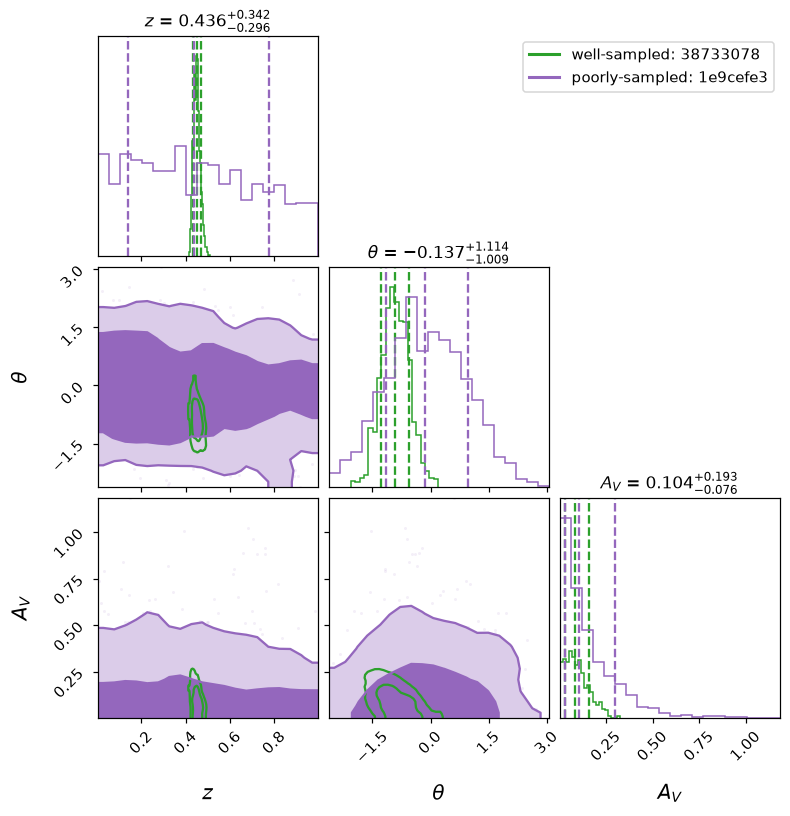

In [125]:
# pick a poorly-sampled SN for contrast, lowest NEPOCH among fitted SNe
poor_cid = fitres.sort_values("NEPOCH").iloc[0]["CID"]

fig, samples_best = corner_for_sn(cid_best, chains, cid_to_idx, color="C2")
fig, samples_poor = corner_for_sn(poor_cid, chains, cid_to_idx, fig=fig, color="C4")

# manual legend since corner doesn't auto-generate one for overlays
from matplotlib.lines import Line2D
fig.legend(
    handles=[Line2D([0], [0], color="C2", lw=2, label=f"well-sampled: {cid_best[:8]}"),
             Line2D([0], [0], color="C4", lw=2, label=f"poorly-sampled: {poor_cid[:8]}")],
    loc="upper right", bbox_to_anchor=(0.95, 0.95),
)
plt.show()

poor_cid = 1e9cefe3-9b60-4b60-a9b7-3d259c92af28, NEPOCH = 1


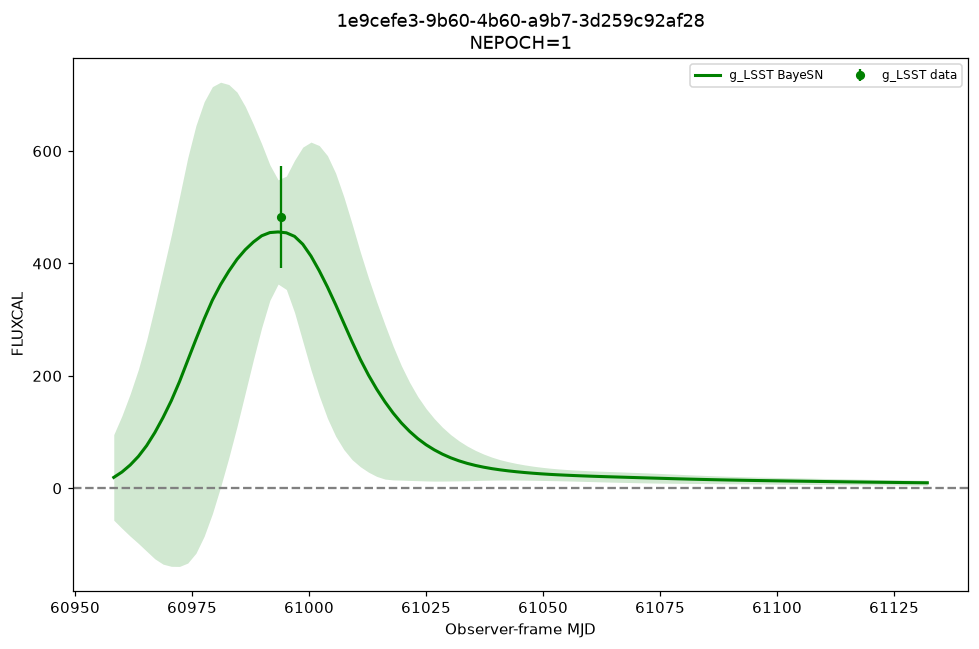

In [126]:
poor_cid = fitres.sort_values("NEPOCH").iloc[0]["CID"]
n_epoch_poor = fitres.loc[fitres.CID == poor_cid, "NEPOCH"].values[0]
print(f"poor_cid = {poor_cid}, NEPOCH = {n_epoch_poor}")

fig, ax = plt.subplots(figsize=(9, 6))
plot_lightcurve_lcplot(poor_cid, ax=ax)
ax.set_title(f"{poor_cid}\nNEPOCH={n_epoch_poor}")
plt.tight_layout()
plt.show()

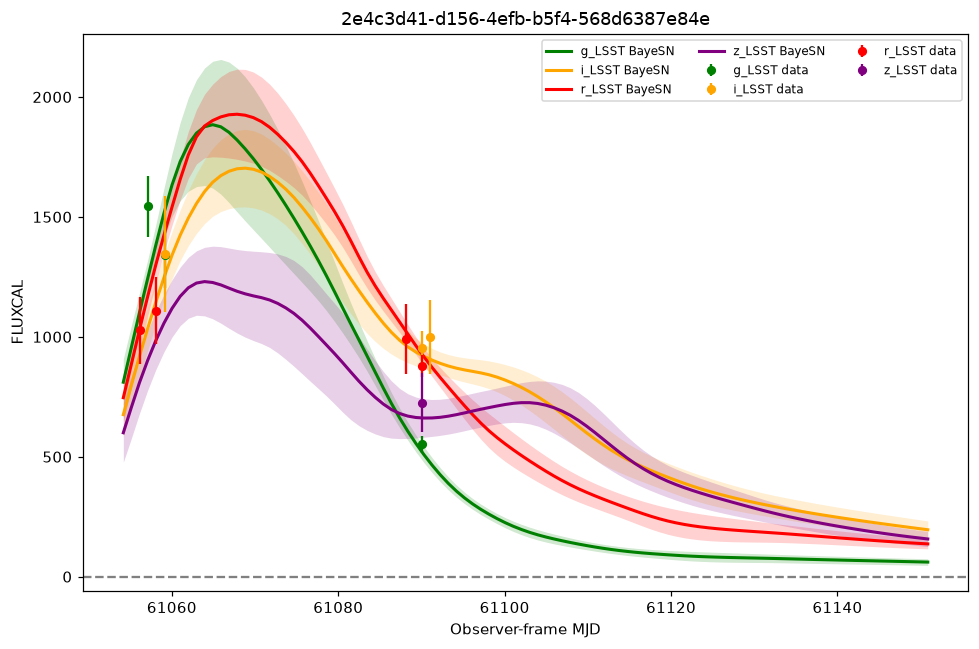

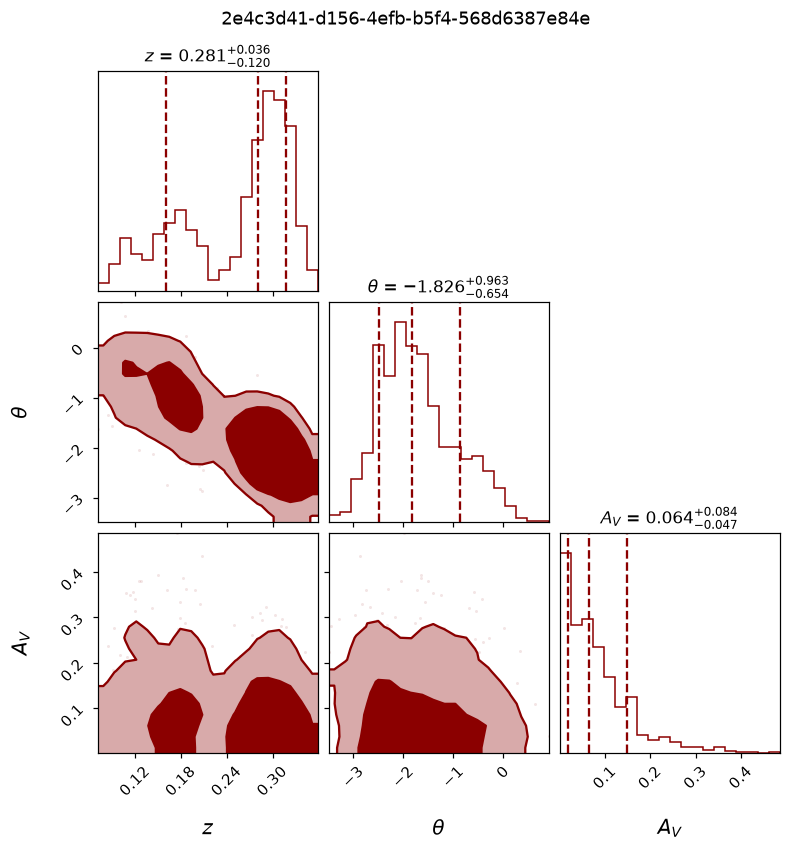

In [128]:
cid_well = "38733078-e3b2-4817-9a86-64cae48a35fb"
cid_sparse = "2e4c3d41-d156-4efb-b5f4-568d6387e84e"

fig, ax = plt.subplots(figsize=(9, 6))
try:
    plot_lightcurve_lcplot(cid_sparse, ax=ax)
except Exception as e:
    print(f"not in LCPLOT ({e}), falling back to raw FITS")
    plot_lightcurve(cid_sparse, ax=ax)
plt.tight_layout()
plt.show()

fig_corner, samples_sparse = corner_for_sn(
    cid_sparse, chains, cid_to_idx,
    params=("z", "theta", "AV"),
    color="darkred",
)
fig_corner.suptitle(f"{cid_sparse}", fontsize=12, y=1.02)
plt.show()

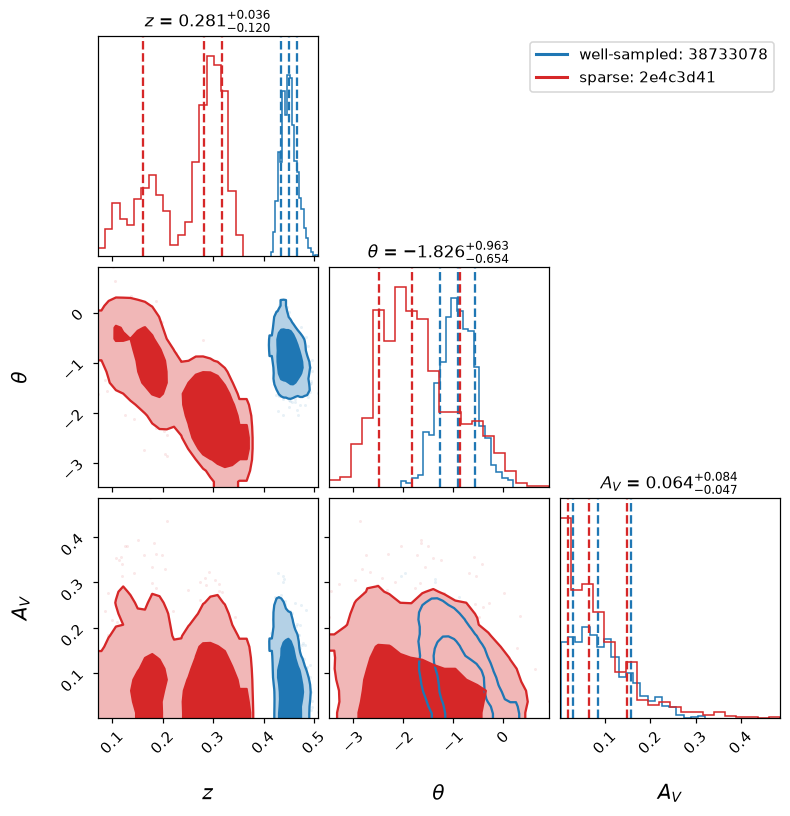

In [129]:
fig, samples_well = corner_for_sn(cid_well, chains, cid_to_idx, color="C0")
fig, samples_sparse = corner_for_sn(cid_sparse, chains, cid_to_idx, fig=fig, color="C3")

from matplotlib.lines import Line2D
fig.legend(
    handles=[
        Line2D([0], [0], color="C0", lw=2, label=f"well-sampled: {cid_well[:8]}"),
        Line2D([0], [0], color="C3", lw=2, label=f"sparse: {cid_sparse[:8]}"),
    ],
    loc="upper right", bbox_to_anchor=(0.95, 0.95),
)
plt.show()